# $\nu_e$ CC Inclusive — event analysis

In [1]:
%matplotlib inline
import os, sys, gc, re, json, warnings, datetime, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import LogNorm
 
CAFPYANA_WD = '/home/castalyf/cafpyana'
for p in [CAFPYANA_WD, CAFPYANA_WD + '/pyanalib', CAFPYANA_WD + '/analysis_village/nueCC']:
    if p not in sys.path:
        sys.path.insert(0, p)
 
# ── What to run ───────────────────────────────────────────────────────────────
RUN_EXPORT   = True    # Part A: ntuples → saved_csvs/ (slow, ~13 GB RSS). False = Part B only.
EXPORT_DATA  = True    # on-beam data rows: Gen1 dev sample only. Keep False for Gen2 until a stage is approved.
DATA_POT_CAP = 1.0e19  # export refuses on-beam data above this POT (open/dev-sample size)
INSPECT      = True    # print the reco/true column names once (to extend the export later)
 
# ── Inputs (same as the data/MC notebook) ─────────────────────────────────────
PRODUCTION = 'gen1_v2'
PROD       = f'/exp/sbnd/data/users/castalyf/nue_sel/production_files/{PRODUCTION}'
DF_OUT_DIR = './nuecc_dfs'
SEL_FILE     = f'{DF_OUT_DIR}/selected_nuecc_qual.df'
PROD_MC    = '/exp/sbnd/data/users/castalyf/nue_sel/production_files/gen1_v2610'   # remade MC (must match nue_selection.ipynb)
DF_FILE      = f'{PROD_MC}/mc1e20_nueCC_2610.df'
LOWE_FILE    = f'{PROD_MC}/mc1e20_lowE_2610.df'
INTIME_FILE  = f'{PROD}/intime_cosmic.df'
DATA_FILE    = f'{PROD}/data_dev.df'
OFFBEAM_FILE = f'{PROD}/data_offbeamlight.df'
TARGET_POT = 6.6e20
KE_MIN     = 500.0     # MeV — leading-shower threshold for exported rows and for data blinding
 
CSV_DIR  = './saved_csvs'
PLOT_DIR = './plots_analysis'
for d in (CSV_DIR, PLOT_DIR):
    os.makedirs(d, exist_ok=True)
 
def savefig(fig, name):
    fig.savefig(os.path.join(PLOT_DIR, f'{name}.png'), dpi=150, bbox_inches='tight')
    display(fig)
    plt.close(fig)
print('config OK')


config OK


## Part 1 — export loaded events to CSV
### 1.1 Export helpers

In [2]:
PID_NAMES = {0: 'photon', 1: 'electron', 2: 'muon', 3: 'pion', 4: 'proton'}
 
# leading-particle fields: output name → (field, sub-field); missing fields are skipped
SHOWER_FIELDS = {
    'id': ('id', ''), 'calo_ke': ('calo_ke', ''), 'ke': ('ke', ''), 'pid': ('pid', ''),
    'start_dedx': ('start_dedx', ''), 'vertex_distance': ('vertex_distance', ''),
    'length': ('length', ''), 'is_primary': ('is_primary', ''), 'is_contained': ('is_contained', ''),
    'primary_score': ('primary_scores', 'I1'),
    'pid_score_photon': ('pid_scores', 'I0'), 'pid_score_electron': ('pid_scores', 'I1'),
    'pid_score_muon': ('pid_scores', 'I2'), 'pid_score_pion': ('pid_scores', 'I3'),
    'pid_score_proton': ('pid_scores', 'I4'),
}
TRACK_FIELDS = {
    'id': ('id', ''), 'pid': ('pid', ''), 'length': ('length', ''), 'ke': ('ke', ''), 'calo_ke': ('calo_ke', ''),
    'csda_ke': ('csda_ke', ''), 'is_contained': ('is_contained', ''), 'is_primary': ('is_primary', ''),
}
# interaction-level fields (first sub-column of each, if present)
INTER_FIELDS = ['id', 'is_contained', 'is_fiducial', 'flash_total_pe', 'flash_times', 'flash_scores',
                'flash_hypo_pe', 'nu_score', 'topology']
 
 
def _col(df, field, sub=''):
    cols = df.columns
    for c in ((field, sub), field):
        if c in cols:
            return c
    for c in cols:
        if isinstance(c, tuple) and c and c[0] == field and (sub == '' or sub in c[1:]):
            return c
    return None
 
 
def _dir_cols(df):
    return [next((c for c in df.columns if 'start_dir' in str(c) and k in str(c)), None)
            for k in ('I0', 'I1', 'I2')]
 
 
def _leading(rp, inter_idx, il, pids, prefix, fields, key='calo_ke'):
    # Leading particle (max `key`) among `pids` per interaction in inter_idx.
    pidc = _col(rp, 'pid')
    keyc = _col(rp, key) or _col(rp, 'ke')
    m = np.asarray(rp.index.droplevel(-1).isin(inter_idx)) & rp[pidc].isin(list(pids)).to_numpy()
    sub = rp.loc[m]
    if sub.empty:
        return pd.DataFrame()
    lead = sub[keyc].astype(float).fillna(-np.inf).groupby(level=il).idxmax()
    ld = sub.loc[pd.MultiIndex.from_tuples(lead.values, names=sub.index.names)]
    out = pd.DataFrame(index=lead.index)
    for name, (f, s) in fields.items():
        c = _col(rp, f, s)
        if c is not None:
            out[prefix + name] = pd.to_numeric(ld[c], errors='coerce').to_numpy(dtype=float)
    d = _dir_cols(rp)
    if all(c is not None for c in d):
        v = ld[d].to_numpy(dtype=float)
        n = np.linalg.norm(v, axis=1)
        n[n == 0] = np.nan
        out[prefix + 'costheta'] = v[:, 2] / n
    return out
 
 
def _mult(rp, inter_idx, il):
    pidc, primc = _col(rp, 'pid'), _col(rp, 'is_primary')
    sub = rp.loc[np.asarray(rp.index.droplevel(-1).isin(inter_idx))]
    pid = sub[pidc]
    out = {}
    for k, n in PID_NAMES.items():
        out[f'n_{n}'] = (pid == k).groupby(level=il).sum()
        if primc is not None:
            out[f'n_{n}_primary'] = ((pid == k) & sub[primc].astype(bool)).groupby(level=il).sum()
    return pd.DataFrame(out)
 
 
def _inter(evtdf, inter_idx, il):
    ri = evtdf['rec']['dlp']
    cols = {}
    for coord, alt in zip('xyz', ('I0', 'I1', 'I2')):
        c = next((cc for cc in [('vertex', coord, ''), ('vertex', coord), ('vertex', alt, ''), ('vertex', alt)]
                  if cc in ri.columns), None)
        if c is not None:
            cols[f'vtx_{coord}'] = c
    for f in INTER_FIELDS:
        c = next((cc for cc in ri.columns if isinstance(cc, tuple) and cc[0] == f), None)
        if c is not None:
            cols[f'int_{f}'] = c
    if not cols:
        return pd.DataFrame()
    sel = ri.loc[np.asarray(ri.index.droplevel(-1).isin(inter_idx)), list(cols.values())]
    g = sel.groupby(level=il).first()
    g.columns = list(cols.keys())
    return g.apply(pd.to_numeric, errors='coerce')
 
 
def _hdr_all(path):
    with pd.HDFStore(path, mode='r') as st:
        keys = sorted((k for k in st.keys() if re.match(r'^/hdr_\d+$', k)),
                      key=lambda k: int(k.rsplit('_', 1)[1]))
        return pd.concat([st[k] for k in keys]) if keys else None
 
 
def _rse(path, inter_index):
    # run/subrun/evt per interaction via hdr keys (index levels 0,1 = __ntuple, entry).
    h = _hdr_all(path)
    if h is None:
        return None
    ev = 'evt' if 'evt' in h.columns else 'event'
    extra = [c for c in ('fno', 'proc', 'cluster') if c in h.columns]
    r = h[['run', 'subrun', ev] + extra].groupby(level=[0, 1]).first()
    r.columns = ['run', 'subrun', 'evt'] + [f'hdr_{c}' for c in extra]
    k = pd.MultiIndex.from_arrays([inter_index.get_level_values(0), inter_index.get_level_values(1)])
    return r.reindex(k)
 
 
def _flags_from_cutflow(cut_flow):
    fv = cut_flow['fiducial']['inter_index']
    return pd.DataFrame({f'sel_{s}': fv.isin(d['inter_index']) for s, d in cut_flow.items()}, index=fv)
 
 
# identification / bookkeeping columns, always written first (left-most) in every CSV
META_COLS = ['run', 'subrun', 'evt', 'sample', 'truth_cat', 'idx0', 'idx1', 'idx2',
             'int_id', 'sh_id', 'e_id', 'trk_id', 'hdr_fno', 'hdr_proc', 'hdr_cluster', 'w_data', 'w_target']
 
 
def order_columns(df):
    df = df.copy()
    for c in ('run', 'subrun', 'evt'):
        if c in df.columns:
            df[c] = pd.to_numeric(df[c], errors='coerce').astype('Int64')
    first = [c for c in META_COLS if c in df.columns]
    return df[first + [c for c in df.columns if c not in first]]
 
 
def _put(t, sub):
    # Copy columns of `sub` into `t`, aligned on the interaction index.
    if sub is None or len(sub) == 0:
        return
    sub = sub.copy()
    sub.index = sub.index.set_names(t.index.names)
    sub = sub[~sub.index.duplicated(keep='first')].reindex(t.index)
    for c in sub.columns:
        t[str(c)] = sub[c].to_numpy()
 
 
def _selection_electron(evtdf, inter_idx):
    # lp_*: the particle the selection cuts on — leading PRIMARY reco electron with KE > 500 MeV
    # (nue_selection.leading_primary_electron, the same one shower_qual_cuts uses)
    import nue_selection as _ns
    lp = _ns.leading_primary_electron(evtdf)
    lp = lp[lp.index.isin(inter_idx)]
    out = pd.DataFrame(index=lp.index)
    for name, (f, s) in SHOWER_FIELDS.items():
        c = _col(lp, f, s)
        if c is not None:
            out['lp_' + name] = pd.to_numeric(lp[c], errors='coerce').to_numpy(dtype=float)
    return out


def build_table(evtdf, flags, sample, path, w_data, w_target, extra=None, blind_data=False,
                truth_cat=None):
    il = list(range(evtdf.index.nlevels - 1))
    names = [f'idx{i}' for i in range(len(il))]
    rp = evtdf['rec']['dlp']['particles']
    flags = flags.copy()
    flags.index = flags.index.set_names(names)
    fv = flags.index[flags['sel_fiducial'].to_numpy(dtype=bool)]
 
    sh = _leading(rp, fv, il, (0, 1), 'sh_', SHOWER_FIELDS)
    sh.index = sh.index.set_names(names)
    keep = sh.index[(sh['sh_calo_ke'] >= KE_MIN).to_numpy()]
    if 'sel_single_electron' in flags and not blind_data:
        keep = keep.union(flags.index[flags['sel_single_electron'].to_numpy(dtype=bool)])
    keep = keep.set_names(names)
 
    t = pd.DataFrame(index=keep)
    _put(t, flags)
    for c in flags.columns:
        t[c] = pd.Series(t[c]).fillna(False).astype(bool).to_numpy()
    _put(t, sh)
    _put(t, _leading(rp, keep, il, (1,), 'e_', SHOWER_FIELDS))
    _put(t, _selection_electron(evtdf, keep))
    _put(t, _leading(rp, keep, il, (2, 3, 4), 'trk_', TRACK_FIELDS, key='length'))
    m = _mult(rp, keep, il)
    _put(t, m)
    for c in m.columns:
        t[c] = pd.Series(t[c]).fillna(0).astype(int).to_numpy()
    _put(t, _inter(evtdf, keep, il))
    try:
        r = _rse(path, keep)
        if r is not None:
            for c in r.columns:
                t[c] = r[c].to_numpy()
    except Exception as e:
        print(f'  [{sample}] run/subrun/evt not added: {e}')
    if extra is not None:
        _put(t, extra)
    if truth_cat is not None:
        t['truth_cat'] = truth_cat
    t['sample'], t['w_data'], t['w_target'] = sample, w_data, w_target
    if blind_data:
        n0 = len(t)
        t = t[t['sh_calo_ke'] >= KE_MIN]
        print(f'  [{sample}] blinding: kept {len(t):,}/{n0:,} rows with sh_calo_ke ≥ {KE_MIN:g} MeV')
    print(f'  [{sample}] {len(t):,} rows × {t.shape[1]} cols')
    return order_columns(t.reset_index())
 
 
CF_ROWS = []
def add_cutflow_flags(sample, sel, w_data, w_target):
    # MC-like samples: counts per stage and truth_cat from a sel_* flag frame.
    for c in [c for c in sel.columns if c.startswith('sel_')]:
        for cat, n in sel.groupby('truth_cat')[c].sum().items():
            CF_ROWS.append(dict(sample=sample, stage=c[4:], truth_cat=int(cat), n_raw=int(n),
                                n_w_data=n * w_data, n_w_target=n * w_target))
 
def add_cutflow_dict(sample, cut_flow, w_data, w_target, truth_cat):
    for s, d in cut_flow.items():
        n = len(d['inter_index'])
        CF_ROWS.append(dict(sample=sample, stage=s, truth_cat=truth_cat, n_raw=n,
                            n_w_data=n * w_data, n_w_target=n * w_target))
 
 
def inspect_columns(evtdf):
    rp, ri = evtdf['rec']['dlp']['particles'], evtdf['rec']['dlp']
    fields = lambda df: sorted({c[0] if isinstance(c, tuple) else c for c in df.columns})
    print('index levels :', evtdf.index.names)
    print('reco particle fields :', fields(rp))
    print('reco interaction fields:', [f for f in fields(ri) if f != 'particles'])
    if 'dlp_true' in evtdf['rec'].columns.get_level_values(0):
        print('true particle fields (kept):', fields(evtdf['rec']['dlp_true']['particles']))
    print('match-like reco columns:', [c for c in rp.columns if 'match' in str(c)][:10])
print('helpers OK')


helpers OK


## 1.2 Load selection, POT and normalizations

In [3]:
if RUN_EXPORT:
    import nue_helpers as nh
    import nue_selection as nue_sel
    from mem_optimizer import load_evtdf_slim
 
    CUT_NAMES   = list(nue_sel.CUT_NAMES_MORE)
    FINAL_STAGE = f'sel_{CUT_NAMES[-1]}'
 
    st = nh.load_sel_topo(SEL_FILE, df_file=DF_FILE)
    sel_topo, pot_scale, statsdf = st['sel_topo'], st['pot_scale'], st['statsdf']
    mc_sample_pot = TARGET_POT / pot_scale
 
    with pd.HDFStore(DATA_FILE, mode='r') as s:
        data_pot = float(s['pot_0']['TOR860'].sum())
    pot_scale_to_data = data_pot / mc_sample_pot
 
    lt = nh.livetime_scales(DATA_FILE, OFFBEAM_FILE, INTIME_FILE)
    offbeam_scale, intime_scale = lt['offbeam_scale'], lt['intime_scale']
    offbeam_scale_t = offbeam_scale * TARGET_POT / data_pot
    intime_scale_t  = intime_scale  * TARGET_POT / data_pot
 
    if EXPORT_DATA and data_pot > DATA_POT_CAP:
        raise RuntimeError(f'Data POT {data_pot:.2e} > DATA_POT_CAP {DATA_POT_CAP:.1e}: '
                           'not an open sample — set EXPORT_DATA=False or get approval first.')
    print(f'FINAL_STAGE={FINAL_STAGE}  MC POT={mc_sample_pot:.3e}  data POT={data_pot:.3e}')
    print(f'offbeam_scale={offbeam_scale:.6f}  intime_scale={intime_scale:.4e}')


sel_topo shape : (3626750, 19)
pot_scale      : 1.1734
n_true_signal  : 11,560
  sel_precut                          sig=11,159  total=3,626,750
  sel_valid_flashmatch                sig=11,159  total=3,626,750
  sel_fiducial                        sig=11,159  total=3,626,750
  sel_single_electron                 sig=10,136  total=   23,829
  sel_electron_primary_score          sig= 9,771  total=   21,628
  sel_electron_pid_score              sig= 8,450  total=   13,139
  sel_vertex_distance                 sig= 7,795  total=   10,803
  sel_start_dedx                      sig= 4,725  total=    5,308
On-beam spills (pot_0, TOR860>0): 927,556  (4.83e+12 POT/spill)
Off-beam gates (noffbeambnb):     83,691,835  → offbeam_scale = 0.010279
In-time generated (ngenevt):      101,920,500  → intime_scale  = 8.440973e-03
Triggered fraction: off-beam 1.98%   in-time 2.08%
FINAL_STAGE=sel_start_dedx  MC POT=5.625e+20  data POT=4.476e+18
offbeam_scale=0.010279  intime_scale=8.4410e-03


## 1.3 Main MC (BNB + cosmics)

In [4]:
if RUN_EXPORT:
    mc_evtdf = load_evtdf_slim(DF_FILE, key=None, mode='reco_min_true')
    if INSPECT:
        inspect_columns(mc_evtdf)
 
    sel_cols = [c for c in sel_topo.columns if c.startswith('sel_')]
    keep_truth = [c for c in ['truth_cat', 'is_sig', 'true_ke', 'true_costheta', 'true_p',
                              'reco_ke', 'reco_costheta', 'reco_p'] if c in sel_topo.columns]
    extra = sel_topo[keep_truth].rename(columns={c: f'ana_{c}' for c in keep_truth if c.startswith('reco_')})
 
    # truth_info (all numeric columns, prefixed ti_) — e.g. interaction mode, true Eν if stored
    ti = statsdf.select_dtypes(include=[np.number, bool])
    ti = ti[[c for c in ti.columns if c != 'truth_cat']]
    ti.columns = [f"ti_{'_'.join(str(p) for p in c if str(p)) if isinstance(c, tuple) else c}" for c in ti.columns]
    if ti.index.nlevels == extra.index.nlevels:
        ti.index = ti.index.set_names(extra.index.names)
        ti = ti[~ti.index.duplicated(keep='first')]
        extra = extra.join(ti, how='left')
    else:
        print(f'truth_info index has {ti.index.nlevels} levels (selection: {extra.index.nlevels}) — ti_ columns skipped')
 
    mc_tab = build_table(mc_evtdf, sel_topo[sel_cols], 'mc', DF_FILE,
                         pot_scale_to_data, pot_scale, extra=extra)
    # every preselected interaction must exist in DF_FILE — otherwise SEL_FILE was made from another MC file
    _miss = mc_tab.loc[mc_tab['sel_fiducial'], 'vtx_x'].isna().mean() if 'vtx_x' in mc_tab else 0.0
    if _miss > 0.01:
        raise RuntimeError(f'{100*_miss:.0f}% of preselected interactions not found in DF_FILE — SEL_FILE was '
                           'made from a different MC file (check DF_FILE vs MERGED_FILE in nue_selection.ipynb)')
    mc_tab.to_csv(f'{CSV_DIR}/events_mc.csv', index=False)
    add_cutflow_flags('mc', sel_topo[sel_cols + ['truth_cat']], pot_scale_to_data, pot_scale)
 
    N_SIG_PRESEL = int(sel_topo['is_sig'].sum())
    # one row per true signal ν (truth_cat==0 would count split ν twice and miss unreconstructed ones)
    N_SIG_TRUTH  = (int(statsdf['is_true_signal'].sum()) if 'is_true_signal' in statsdf.columns
                    else int((statsdf['truth_cat'] == 0).sum()) if 'truth_cat' in statsdf.columns else None)
    del mc_evtdf, extra, ti
    gc.collect()



load_evtdf_slim  mode='reco_min_true'  keys=4/4 downcast=True
  columns from '/evt_0':
  Total cols :  393  →  kept:   94  dropped:  299  (76% reduced)
  Group                            all   kept
  ------------------------------------------
  dlp_reco_interaction              32     20  ← dropped 12
  dlp_reco_particle                 72     54  ← dropped 18
  dlp_true_interaction              68      0  ← dropped 68
  dlp_true_particle                113     16  ← dropped 97
  mcnu                             104      0  ← dropped 104
  index_artifact                     4      4
  other                              0      0

  [ 1/4] /evt_0   rows=4,252,904  cum=  4,252,904  RSS=5.30 GB
  [ 2/4] /evt_1   rows=4,250,248  cum=  8,503,152  RSS=6.71 GB
  [ 3/4] /evt_2   rows=4,237,837  cum= 12,740,989  RSS=8.12 GB
  [ 4/4] /evt_3   rows=4,241,374  cum= 16,982,363  RSS=9.55 GB
  Concatenating 4 parts (16,982,363 rows) ...
  Final shape: (16982363, 94)  (~5.80 GB)
  [after evtdf load] R

/tmp/ipykernel_2075/3628219282.py:141: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  t[str(c)] = sub[c].to_numpy()
/tmp/ipykernel_2075/3628219282.py:141: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  t[str(c)] = sub[c].to_numpy()
/tmp/ipykernel_2075/3628219282.py:141: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = fr

  [mc] 55,246 rows × 115 cols


## 1.4 Low-energy dirt

In [5]:
if RUN_EXPORT:
    lowE = nh.load_lowE_sample(LOWE_FILE, TARGET_POT, data_pot)
    lsel = lowE['sel']
    lsel_cols = [c for c in lsel.columns if c.startswith('sel_')]
    lextra = lsel[['truth_cat', 'is_sig', 'reco_ke', 'reco_costheta', 'reco_p']].rename(
        columns={'reco_ke': 'ana_reco_ke', 'reco_costheta': 'ana_reco_costheta', 'reco_p': 'ana_reco_p'})
    dirt_tab = build_table(lowE['evtdf'], lsel[lsel_cols], 'dirt', LOWE_FILE,
                           lowE['pot_scale_to_data'], lowE['pot_scale'], extra=lextra)
    dirt_tab.to_csv(f'{CSV_DIR}/events_dirt.csv', index=False)
    add_cutflow_flags('dirt', lsel[lsel_cols + ['truth_cat']], lowE['pot_scale_to_data'], lowE['pot_scale'])
    LOWE_POT_SCALES = (lowE['pot_scale_to_data'], lowE['pot_scale'])
    del lowE, lsel, lextra
    gc.collect()



load_evtdf_slim  mode='reco_min_true'  keys=5/5 downcast=True
  columns from '/evt_0':
  Total cols :  393  →  kept:   94  dropped:  299  (76% reduced)
  Group                            all   kept
  ------------------------------------------
  dlp_reco_interaction              32     20  ← dropped 12
  dlp_reco_particle                 72     54  ← dropped 18
  dlp_true_interaction              68      0  ← dropped 68
  dlp_true_particle                113     16  ← dropped 97
  mcnu                             104      0  ← dropped 104
  index_artifact                     4      4
  other                              0      0

  [ 1/5] /evt_0   rows=  190,498  cum=    190,498  RSS=7.46 GB
  [ 2/5] /evt_1   rows=  190,051  cum=    380,549  RSS=7.46 GB
  [ 3/5] /evt_2   rows=  189,190  cum=    569,739  RSS=7.46 GB
  [ 4/5] /evt_3   rows=  187,721  cum=    757,460  RSS=7.46 GB
  [ 5/5] /evt_4   rows=  100,528  cum=    857,988  RSS=7.46 GB
  Concatenating 5 parts (857,988 rows) ...
  Fi

Building cut flow:   0%|          | 0/4 [00:00<?, ?it/s]

Shower quality cuts:   0%|          | 0/4 [00:00<?, ?it/s]

LowE: dropped 292,647 cosmic interactions (predicted by off-beam + main MC)
  precut                        :   89,945
  valid_flashmatch              :   89,945
  fiducial                      :   89,945
  single_electron               :       13
  electron_primary_score        :       13
  electron_pid_score            :        3
  vertex_distance               :        1
  start_dedx                    :        0
  [dirt] 14 rows × 85 cols


## 1.5 Off-beam data and in-time cosmic MC

In [6]:
if RUN_EXPORT:
    for sample, path, w_d, w_t, tcat in [('offbeam', OFFBEAM_FILE, offbeam_scale, offbeam_scale_t, 8),
                                         ('intime',  INTIME_FILE,  intime_scale,  intime_scale_t, 10)]:
        evt, _ = nh.patch_vertex_cols(pd.read_hdf(path, key='evt_0'))
        with warnings.catch_warnings():
            warnings.simplefilter('ignore')
            cf = nue_sel.shower_qual_cuts(evt)
        tab = build_table(evt, _flags_from_cutflow(cf), sample, path, w_d, w_t, truth_cat=tcat)
        tab.to_csv(f'{CSV_DIR}/events_{sample}.csv', index=False)
        add_cutflow_dict(sample, cf, w_d, w_t, tcat)
        del evt, cf, tab
        gc.collect()


Building cut flow:   0%|          | 0/4 [00:00<?, ?it/s]

Shower quality cuts:   0%|          | 0/4 [00:00<?, ?it/s]

  [offbeam] 3,636 rows × 92 cols


Building cut flow:   0%|          | 0/4 [00:00<?, ?it/s]

Shower quality cuts:   0%|          | 0/4 [00:00<?, ?it/s]

  [intime] 3,574 rows × 92 cols


## 1.6 On-beam data (dev sample only, blinded below KE_MIN)

In [7]:
if RUN_EXPORT and EXPORT_DATA:
    data = nh.load_onbeam_data(DATA_FILE, TARGET_POT, pot_scale)
    data_tab = build_table(data['evtdf'], _flags_from_cutflow(data['cut_flow']), 'data', DATA_FILE,
                           1.0, np.nan, blind_data=True, truth_cat=-1)
    data_tab.to_csv(f'{CSV_DIR}/events_data.csv', index=False)
    add_cutflow_dict('data', data['cut_flow'], 1.0, np.nan, -1)
 
    # POT per run (for ≤1e19-per-plot time slicing)
    h = _hdr_all(DATA_FILE)
    if h is not None and {'pot', 'run'} <= set(h.columns):
        first = h['first_in_subrun'].astype(bool) if 'first_in_subrun' in h else ~h.duplicated(['run', 'subrun'])
        pbr = h[first].groupby('run')['pot'].sum().rename('pot').reset_index()
        pbr.to_csv(f'{CSV_DIR}/data_pot_by_run.csv', index=False)
        print(f'POT by run: {len(pbr)} runs, Σ={pbr.pot.sum():.3e} (TOR860 total {data_pot:.3e})')
    del data
    gc.collect()
elif RUN_EXPORT:
    for f in ('events_data.csv', 'data_pot_by_run.csv'):
        if os.path.exists(f'{CSV_DIR}/{f}'):
            os.remove(f'{CSV_DIR}/{f}')
            print(f'removed stale {f} (EXPORT_DATA=False)')


Data: (156521, 100)  POT=4.476e+18  pot_scale_to_data=0.0080  renamed 3 vertex cols


Building cut flow:   0%|          | 0/4 [00:00<?, ?it/s]

Shower quality cuts:   0%|          | 0/4 [00:00<?, ?it/s]

Data cut flow:
  precut                        :   39,225
  valid_flashmatch              :   39,225
  fiducial                      :   39,225
  single_electron               :      206
  electron_primary_score        :      190
  electron_pid_score            :      114
  vertex_distance               :       91
  start_dedx                    :       35
  [data] blinding: kept 412/412 rows with sh_calo_ke ≥ 500 MeV
  [data] 412 rows × 92 cols
POT by run: 2 runs, Σ=4.518e+18 (TOR860 total 4.476e+18)


## 1.7 Cut flow + metadata

In [8]:
COLUMN_DOC = {
    'idx0, idx1, idx2': 'interaction index (__ntuple, entry, rec.dlp index) — joins back to the HDF5 files',
    'run, subrun, evt': 'from hdr_* keys (use these to find the event in the SPINE HDF5 files / spinal-tap)',
    'int_id, sh_id, e_id, trk_id': 'SPINE reco interaction id and particle ids (what spinal-tap displays)',
    'hdr_fno, hdr_proc, hdr_cluster': 'grid-job bookkeeping from hdr, if present',
    'sample': 'mc | dirt | offbeam | intime | data',
    'w_data': 'weight to the on-beam data POT of DATA_FILE (data rows = 1)',
    'w_target': 'weight to TARGET_POT (off-beam/in-time scaled by TARGET_POT/data POT)',
    'truth_cat': '0 νe CC FV, 1 νe CC out-FV, 2 νμ CC π0, 3 NC π0, 4 other νμ CC, 5 other NC, 6 other ν, '
                 '7 cosmic (MC); 8 off-beam, 10 in-time MC, -1 data',
    'is_sig': 'true signal (truth_cat 0)',
    'sel_<stage>': 'passes the cumulative selection stage <stage> (nue_selection.shower_qual_cuts)',
    'sh_*': 'leading e/γ shower (SPINE PID 0 or 1, max calo_ke)',
    'e_*': 'leading SPINE-electron (PID 1, max calo_ke; any primary flag / KE)',
    'lp_*': 'leading PRIMARY SPINE-electron with KE > 500 MeV — the particle the selection cuts on',
    'trk_*': 'longest track (PID 2,3,4)',
    'n_<pid>[_primary]': 'reco particle multiplicities',
    'vtx_x/y/z, int_*': 'reco interaction vertex and interaction-level fields',
    'ana_reco_ke/costheta/p': 'leading-electron kinematics as stored in the selection df',
    'true_ke/costheta/p': 'true electron kinematics (signal)',
    'ti_*': 'numeric truth_info columns',
}
 
if RUN_EXPORT:
    if CF_ROWS:
       pd.DataFrame(CF_ROWS).to_csv(f'{CSV_DIR}/cutflow.csv', index=False)
    else:
       print('CF_ROWS is empty (A.3–A.6 not run in this session) → cutflow.csv left untouched')
    try:
        git = subprocess.run(['git', '-C', CAFPYANA_WD, 'rev-parse', '--short', 'HEAD'],
                             capture_output=True, text=True).stdout.strip()
    except Exception:
        git = ''
    thr = {k: getattr(nue_sel, k) for k in dir(nue_sel)
           if k.isupper() and isinstance(getattr(nue_sel, k), (int, float, str, list, tuple))}
    meta = dict(
        created=datetime.datetime.now().isoformat(timespec='seconds'), production=PRODUCTION,
        cafpyana_git=git, files=dict(sel=SEL_FILE, mc=DF_FILE, dirt=LOWE_FILE, intime=INTIME_FILE,
                                     data=DATA_FILE, offbeam=OFFBEAM_FILE),
        target_pot=TARGET_POT, data_pot=data_pot, mc_sample_pot=mc_sample_pot,
        scales=dict(mc_to_target=pot_scale, mc_to_data=pot_scale_to_data,
                    dirt_to_data=LOWE_POT_SCALES[0], dirt_to_target=LOWE_POT_SCALES[1],
                    offbeam_to_data=offbeam_scale, offbeam_to_target=offbeam_scale_t,
                    intime_to_data=intime_scale, intime_to_target=intime_scale_t,
                    beam_duty_fraction=nh.BEAM_DUTY_FRACTION),
        livetime=dict(onbeam_spills=lt['onbeam_nspills'], offbeam_gates=lt['offbeam_ngates'],
                      intime_ngenevt=lt['intime_ngenevt']),
        ke_min_mev=KE_MIN, final_stage=FINAL_STAGE, cut_names=CUT_NAMES, thresholds=thr,
        n_sig_presel=N_SIG_PRESEL, n_sig_truth_info=N_SIG_TRUTH,
        data_exported=bool(EXPORT_DATA), data_blinded_below_mev=KE_MIN,
        csv_files=sorted(f for f in os.listdir(CSV_DIR) if f.endswith('.csv')),
        columns=COLUMN_DOC)
    with open(f'{CSV_DIR}/metadata.json', 'w') as f:
        json.dump(meta, f, indent=1, default=str)
    print(json.dumps({k: v for k, v in meta.items() if k not in ('thresholds', 'columns')}, indent=1, default=str))


{
 "created": "2026-11-02T19:34:08",
 "production": "gen1_v2",
 "cafpyana_git": "4132c86",
 "files": {
  "sel": "./nuecc_dfs/selected_nuecc_qual.df",
  "mc": "/exp/sbnd/data/users/castalyf/nue_sel/production_files/gen1_v2610/mc1e20_nueCC_2610.df",
  "dirt": "/exp/sbnd/data/users/castalyf/nue_sel/production_files/gen1_v2610/mc1e20_lowE_2610.df",
  "intime": "/exp/sbnd/data/users/castalyf/nue_sel/production_files/gen1_v2/intime_cosmic.df",
  "data": "/exp/sbnd/data/users/castalyf/nue_sel/production_files/gen1_v2/data_dev.df",
  "offbeam": "/exp/sbnd/data/users/castalyf/nue_sel/production_files/gen1_v2/data_offbeamlight.df"
 },
 "target_pot": 6.6e+20,
 "data_pot": 4.4759040289784463e+18,
 "mc_sample_pot": 5.624547634588571e+20,
 "scales": {
  "mc_to_target": 1.173427700996399,
  "mc_to_data": 0.007957802688794997,
  "dirt_to_data": 0.01316629537672392,
  "dirt_to_target": 1.941452473595839,
  "offbeam_to_data": 0.010279475769649452,
  "offbeam_to_target": 1.5157728950495575,
  "intime_to_

# Part 2 — analysis plots from the CSVs
## 2.0 Load

In [9]:
meta = json.load(open(f'{CSV_DIR}/metadata.json'))
EV = {}
for s in ['mc', 'dirt', 'offbeam', 'intime', 'data']:
    p = f'{CSV_DIR}/events_{s}.csv'
    if os.path.exists(p):
        raw = pd.read_csv(p, low_memory=False)
        EV[s] = order_columns(raw)
        if list(EV[s].columns) != list(raw.columns):      # CSVs from an earlier export: rewrite once
            EV[s].to_csv(p, index=False)
            print(f'  reordered columns of {os.path.basename(p)} (identifiers first)')
        print(f'{s:<8s} {EV[s].shape}   first cols: {list(EV[s].columns[:8])}')
CF = pd.read_csv(f'{CSV_DIR}/cutflow.csv')
 
KE_MIN      = meta['ke_min_mev']
THR         = meta['thresholds']
FINAL       = meta['final_stage']
TARGET_POT  = meta['target_pot']
DATA_POT    = meta['data_pot']
STAGES      = meta['cut_names']
# data may only be drawn for the Gen1 open sample; for Gen2 this stays False until approved
SHOW_DATA   = ('data' in EV) and meta['production'].lower().startswith('gen1')
for d in EV.values():
    for c in [c for c in d.columns if c.startswith('sel_')]:
        d[c] = d[c].fillna(False).astype(bool)
print(f"production={meta['production']}  final={FINAL}  data POT={DATA_POT:.3e}  SHOW_DATA={SHOW_DATA}")


mc       (55246, 118)   first cols: ['run', 'subrun', 'evt', 'sample', 'truth_cat', 'idx0', 'idx1', 'idx2']
dirt     (14, 88)   first cols: ['run', 'subrun', 'evt', 'sample', 'truth_cat', 'idx0', 'idx1', 'idx2']
offbeam  (3636, 95)   first cols: ['run', 'subrun', 'evt', 'sample', 'truth_cat', 'idx0', 'idx1', 'idx2']
intime   (3574, 95)   first cols: ['run', 'subrun', 'evt', 'sample', 'truth_cat', 'idx0', 'idx1', 'idx2']
data     (412, 95)   first cols: ['run', 'subrun', 'evt', 'sample', 'truth_cat', 'idx0', 'idx1', 'idx2']
production=gen1_v2  final=sel_start_dedx  data POT=4.476e+18  SHOW_DATA=True


In [10]:
dirt = EV['dirt'][EV['dirt'][FINAL]]
w = meta['scales']['dirt_to_data']
cos = dirt['ana_reco_costheta'] if 'ana_reco_costheta' in dirt else dirt['sh_costheta']
tab = pd.crosstab(dirt['truth_cat'], pd.cut(cos, [-1, 0.5, 0.75, 0.85, 0.925, 1.0], include_lowest=True))
print('raw dirt events at final selection, truth_cat × cosθ bin');      display(tab)
print('scaled to data POT');                                             display((tab * w).round(2))
print(dirt.loc[cos < 0.5, ['vtx_x', 'vtx_y', 'vtx_z']].describe().round(1))

raw dirt events at final selection, truth_cat × cosθ bin


ana_reco_costheta
truth_cat


scaled to data POT


ana_reco_costheta
truth_cat


       vtx_x  vtx_y  vtx_z
count    0.0    0.0    0.0
mean     NaN    NaN    NaN
std      NaN    NaN    NaN
min      NaN    NaN    NaN
25%      NaN    NaN    NaN
50%      NaN    NaN    NaN
75%      NaN    NaN    NaN
max      NaN    NaN    NaN


In [11]:
from mem_optimizer import load_evtdf_slim
ev = load_evtdf_slim(DF_FILE, key='evt_0', mode='reco_min_true', verbose=False)
ti = pd.read_hdf(DF_FILE, key='truth_info_0')
tp = ev['rec']['dlp_true']['particles']
il = list(range(ev.index.nlevels - 1))
col = lambda f: next(c for c in tp.columns if (c[0] if isinstance(c, tuple) else c) == f)
prim = tp[col('is_primary')] == 1
cnt = lambda m: m.groupby(level=il).sum()
diag = pd.DataFrame({
    'n_reco_on_true_e>500': cnt((tp[col('pid')] == 1) & prim & (tp[col('ke')] > 500)),
    'n_reco_on_true_e_any': cnt((tp[col('pid')] == 1) & prim),
    'n_reco_on_true_mu':    cnt((tp[col('pid')] == 2) & prim),
    'n_reco_on_positron':   cnt(tp[col('pdg_code')] == -11),
})
cat7 = ti.index[(ti['truth_cat'] == 6) & ti['passed_presel']]   # other ν
d7 = diag.reindex(cat7).dropna()
print(f'{len(d7)} other-ν (cat 6) preselected interactions in evt_0')
for c in d7.columns:
    print(f'  {c:<24s}', d7[c].astype(int).value_counts().sort_index().to_dict())

16180 other-ν (cat 6) preselected interactions in evt_0
  n_reco_on_true_e>500     {0: 16169, 1: 11}
  n_reco_on_true_e_any     {0: 14506, 1: 1361, 2: 277, 3: 30, 4: 5, 7: 1}
  n_reco_on_true_mu        {0: 6137, 1: 8961, 2: 1030, 3: 50, 4: 2}
  n_reco_on_positron       {0: 12808, 1: 2818, 2: 466, 3: 75, 4: 9, 5: 4}


## 2.1 Categories, prediction frames, region definitions

In [12]:
CAT = {0: (r'$\nu_e$ CC (FV)', '#56B4E9'), 1: (r'$\nu_e$ CC (out FV)', '#0072B2'),
       2: (r'$\nu_\mu$ CC $\pi^0$', 'green'), 3: (r'NC $\pi^0$', '#009E73'),
       4: (r'Other $\nu_\mu$ CC', '#E69F00'), 5: ('Other NC', '#CC79A7'),
       6: (r'Other $\nu$', '#D55E00'), 7: ('Cosmic (MC)', '#F0E442'),
       9: (r'Dirt $\nu$', '#BFB89A'), 8: ('Off-beam', '#7F7F7F')}
ORDER = [0, 1, 2, 3, 4, 5, 6, 7, 9, 8]
PIDCAT = {0: ('photon', '#CC79A7'), 1: ('electron', '#9B8EC4'), 2: ('muon', '#56C8C8'),
          3: ('pion', '#88CCAA'), 4: ('proton', '#AADDAA')}
 
 
def prediction(weight):
    # MC + dirt + off-beam, one row per interaction, column w = chosen weight, pcat = plot category
    parts = []
    for s, cat in [('mc', None), ('dirt', 9), ('offbeam', 8)]:
        if s not in EV:
            continue
        d = EV[s].copy()
        d['pcat'] = d['truth_cat'].fillna(7).astype(int) if cat is None else cat
        d['w'] = d[weight]
        parts.append(d)
    p = pd.concat(parts, ignore_index=True)
    for c in [c for c in p.columns if c.startswith('sel_')]:
        p[c] = p[c].fillna(False).astype(bool)
    return p
 
 
PRED_T = prediction('w_target')     # at TARGET_POT
PRED_D = prediction('w_data')       # at the data POT
DATA   = EV['data'] if SHOW_DATA else None
 
# selection electron columns (lp_*); CSVs exported before lp_* existed fall back to e_*
EP = 'lp_' if 'lp_start_dedx' in EV['mc'].columns else 'e_'
if EP == 'e_':
    print("NOTE: CSVs have no lp_* columns — re-run the export (RUN_EXPORT=True); using e_* (not the selection's electron)")

SHOWER = lambda d: d['sh_calo_ke'] >= KE_MIN     # FV + leading e/γ shower ≥ KE_MIN ("neutrino candidate")
 
 
def box(d, gap_min=2.0, dedx=(3.0, 6.0), v='sh_'):
    return SHOWER(d) & d[v + 'start_dedx'].between(*dedx, inclusive='neither') & (d[v + 'vertex_distance'] > gap_min)
 
 
SIDEBANDS = {
    'Lynn TN: gap>2, 3<dE/dx<6':       lambda d: box(d, 2.0),
    'Lynn DAP cons.: gap>1, 3–6':      lambda d: box(d, 1.0),
    'Lynn DAP loose: gap>0.1, 3–6':    lambda d: box(d, 0.1),
    'SPINE γ-PID leading shower':      lambda d: SHOWER(d) & (d['sh_pid'] == 0),
    'SPINE γ-PID + Lynn TN box':       lambda d: box(d, 2.0) & (d['sh_pid'] == 0),
}
_need = ['THRESH_VERTEX_DIST', 'THRESH_PID_SCORE', 'THRESH_SB_DEDX_LO', 'THRESH_SB_DEDX_HI']
if all(k in THR for k in _need):
    SIDEBANDS['current notebook (topology, PID-score inverted)'] = lambda d: (
        d['sel_single_electron'] & (d[EP + 'vertex_distance'] > THR['THRESH_VERTEX_DIST'])
        & (d[EP + 'pid_score_electron'] < THR['THRESH_PID_SCORE'])
        & d[EP + 'start_dedx'].between(THR['THRESH_SB_DEDX_LO'], THR['THRESH_SB_DEDX_HI'], inclusive='neither'))
if 'int_is_contained' in PRED_T.columns:
    SIDEBANDS['Lynn TN box + contained (≈D1)'] = lambda d: box(d, 2.0) & (d['int_is_contained'] == 1)
 
SB_CHOICE = 'Lynn TN: gap>2, 3<dE/dx<6'     # sideband used in B.4/B.6/B.8
 
 
def in_sb(d, name):
    # sideband events, always orthogonal to the final signal selection
    return SIDEBANDS[name](d).fillna(False) & ~d[FINAL]
 
 
def stacked(ax, d, var, bins, cat='pcat', cats=CAT, order=ORDER, scale=1.0):
    bottom = np.zeros(len(bins) - 1)
    for c in order:
        m = (d[cat] == c).to_numpy()
        if not m.any():
            continue
        x = d.loc[m, var].clip(bins[0], bins[-1] - 1e-9)
        h, _ = np.histogram(x, bins=bins, weights=d.loc[m, 'w'] * scale)
        if h.sum() <= 0:
            continue
        ax.bar(bins[:-1], h, width=np.diff(bins), bottom=bottom, align='edge', color=cats[c][1],
               edgecolor='none', label=f'{cats[c][0]} ({h.sum():.0f}, {100*h.sum()/max(d.w.sum()*scale,1e-9):.1f}%)')
        bottom += h
    return bottom
print('sidebands:', list(SIDEBANDS))


sidebands: ['Lynn TN: gap>2, 3<dE/dx<6', 'Lynn DAP cons.: gap>1, 3–6', 'Lynn DAP loose: gap>0.1, 3–6', 'SPINE γ-PID leading shower', 'SPINE γ-PID + Lynn TN box', 'current notebook (topology, PID-score inverted)', 'Lynn TN box + contained (≈D1)']


## 2.2 Sideband regions in dE/dx – conversion gap (Lynn DAP Fig. 2 style)
MC only, FV + leading e/γ shower ≥ KE_MIN (Lynn applied θ_open > 0.1 rad first; SPINE has no opening angle, so nothing is pre-applied).
Gap = 0 is drawn in the lowest bin.

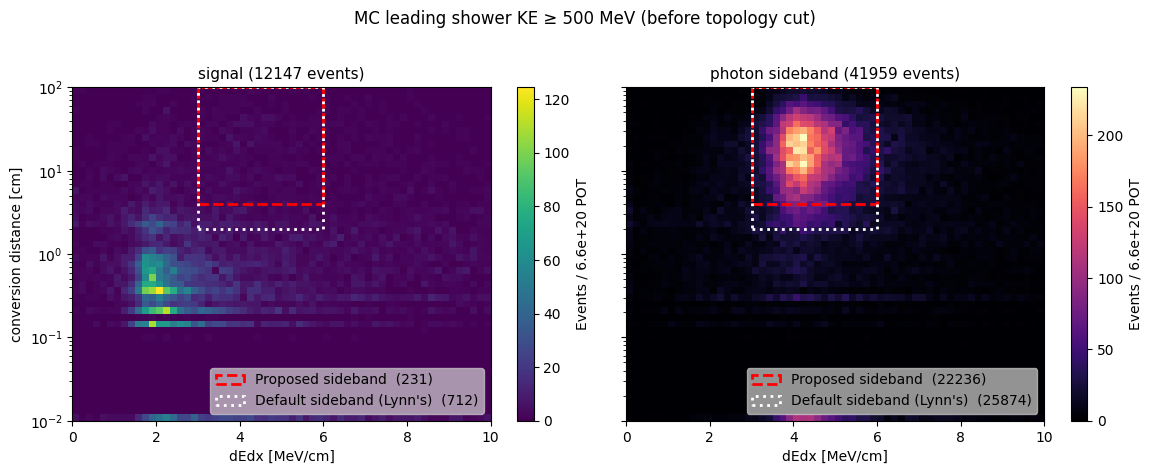

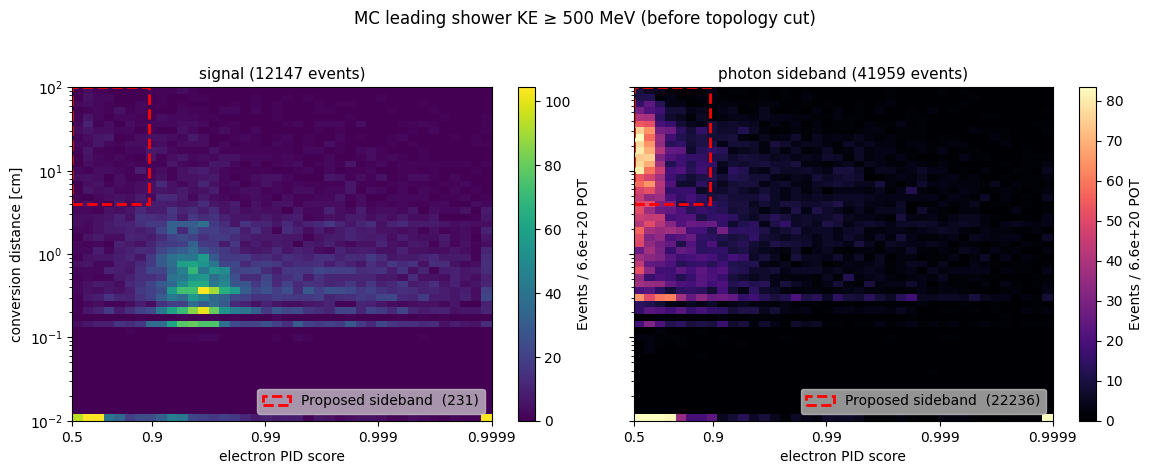

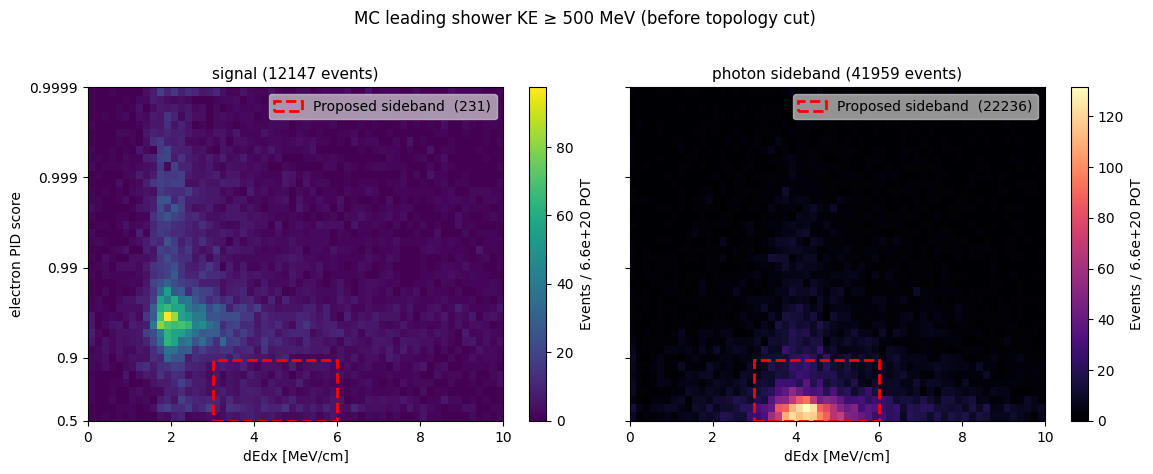

In [13]:
# 2D sideband views, signal vs photon sideband. Three projections per population:
#   dE/dx vs gap  (my SB box + Lynn's TN box),  PID vs gap  and  dE/dx vs PID  (my SB box only).
# Axes: gap on a log scale (gap = 0 is drawn in the lowest bin); PID score on a log scale in
# (1 − score), so the region near 1.0, where most events sit, is stretched out.
# Legend numbers = events in that panel passing ALL conditions of the box (not only the two drawn).

MY_SB = dict(  # current sideband definition (nue_selection THRESH_*)
    label="Proposed sideband",
    cuts={'gap':  (THR.get('THRESH_VERTEX_DIST', 3.45), np.inf),
          'dedx': (THR.get('THRESH_SB_DEDX_LO', 3.0), THR.get('THRESH_SB_DEDX_HI', 6.0)),
          'pid':  (-np.inf, THR.get('THRESH_PID_SCORE', 0.91))},
    color='red', ls='--')
LYNN_SB = dict(label="Default sideband (Lynn's)",
               cuts={'gap': (2.0, np.inf), 'dedx': (3.0, 6.0)},
               color='white', ls=':')

PID_FLOOR = 1e-4                       # axis ends at PID = 1 − 1e-4; scores above go in the last bin
_pid_fwd = lambda p: -np.log10(np.clip(1.0 - np.asarray(p, float), PID_FLOOR * 1e-2, None))
_pid_inv = lambda t: 1.0 - 10.0 ** (-np.asarray(t, float))

AXES = {
    # key: (column suffix, bin edges, label, scale)
    'dedx': (
        'start_dedx',
        np.linspace(0, 10, 61),
        'dEdx [MeV/cm]',
        'linear',
    ),
    'gap': (
        'vertex_distance',
        np.logspace(-2, 2, 51),
        'conversion distance [cm]',
        'log',
    ),
    'pid': (
        'pid_score_electron',
        1.0 - np.logspace(
            np.log10(0.5),
            np.log10(PID_FLOOR),
            41,
        ),
        'electron PID score',
        'pid',
    ),
}


def _axis_values(dp, v, key):
    col, edges, _, scale = AXES[key]
    x = dp[v + col].to_numpy(float)
    if scale == 'log':          # gap = 0 → lowest bin
        x = np.where(np.isfinite(x), np.maximum(x, edges[0] * 1.001), x)
    elif scale == 'pid':        # scores ≈ 1 → last bin
        x = np.where(np.isfinite(x), np.minimum(x, edges[-1] - PID_FLOOR * 1e-3), x)
    return x


def _set_scale(ax, key, which):
    _, edges, _, scale = AXES[key]
    setlim, setscale, setticks, setlabels = (
        (ax.set_xlim, ax.set_xscale, ax.set_xticks, ax.set_xticklabels) if which == 'x'
        else (ax.set_ylim, ax.set_yscale, ax.set_yticks, ax.set_yticklabels))
    if scale == 'log':
        setscale('log')
    elif scale == 'pid':
        setscale('function', functions=(_pid_fwd, _pid_inv))
        ticks = [0.5, 0.9, 0.99, 0.999, 0.9999]
        setticks(ticks); setlabels([f'{t:g}' for t in ticks])
    setlim(edges[0], edges[-1])


def _in_box(d, v, box):
    m = pd.Series(True, index=d.index)
    for key, (lo, hi) in box['cuts'].items():
        x = d[v + AXES[key][0]]
        m &= (x > lo) & (x < hi)
    return m.fillna(False)


def fig_sb2d(pre, v, xkey, ykey, boxes, name, suptitle='', colorbar=True):
    d = PRED_T[pre(PRED_T).fillna(False)]
    panels = [('signal', d['pcat'] == 0, 'viridis'),
              ('photon sideband', d['pcat'].isin([2, 3]), 'magma')]
    (_, xb, xl, _), (_, yb, yl, _) = AXES[xkey], AXES[ykey]
    fig, axes = plt.subplots(1, len(panels), figsize=(5.4 * len(panels) + (1 if colorbar else 0), 4.6),
                             sharey=True, squeeze=False)
    for ax, (title, m, cmap) in zip(axes[0], panels):
        cm = plt.get_cmap(cmap)
        ax.set_facecolor(cm(0.0))
        dp = d[m.to_numpy()]
        x, y, w = _axis_values(dp, v, xkey), _axis_values(dp, v, ykey), dp['w'].to_numpy(float)
        ok = np.isfinite(x) & np.isfinite(y)
        h, _, _ = np.histogram2d(x[ok], y[ok], bins=[xb, yb], weights=w[ok])
        # gap = 0 (shower attached to the vertex) piles up in the lowest gap row: keep it out of the colour range
        vmax = h[:, 1:].max() if (ykey == 'gap' and h[:, 1:].max() > 0) else h.max()
        im = ax.pcolormesh(xb, yb, h.T, cmap=cm, norm=plt.Normalize(vmin=0, vmax=max(vmax, 1e-9)), shading='flat')
        if colorbar:
            fig.colorbar(im, ax=ax, label=f'Events / {TARGET_POT:.1e} POT')
        for box in boxes:
            (x0, x1), (y0, y1) = [box['cuts'].get(k, (-np.inf, np.inf)) for k in (xkey, ykey)]
            x0, x1 = max(x0, xb[0]), min(x1, xb[-1])
            y0, y1 = max(y0, yb[0]), min(y1, yb[-1])
            n_in = dp.loc[_in_box(dp, v, box), 'w'].sum()
            ax.add_patch(mpatches.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec=box['color'],
                                            ls=box['ls'], lw=2, label=f"{box['label']}  ({n_in:.0f})"))
        _set_scale(ax, xkey, 'x'); _set_scale(ax, ykey, 'y')
        ax.set_title(f'{title} ({w.sum():.0f} events)', fontsize=11)
        ax.set_xlabel(xl)
        ax.legend(loc='lower right' if ykey == 'gap' else 'upper right', fontsize=10,
                  facecolor='lightgray', framealpha=0.7)
    axes[0][0].set_ylabel(yl)
    if suptitle:
        fig.suptitle(suptitle, y=1.02)
    fig.tight_layout()
    savefig(fig, name)


def sb2d_set(pre, v, tag, suptitle):
    fig_sb2d(pre, v, 'dedx', 'gap', [MY_SB, LYNN_SB], f'sb2d_{tag}_dedx_gap', suptitle)
    fig_sb2d(pre, v, 'pid',  'gap', [MY_SB],          f'sb2d_{tag}_pid_gap',  suptitle)
    fig_sb2d(pre, v, 'dedx', 'pid', [MY_SB],          f'sb2d_{tag}_dedx_pid', suptitle)


# Set 1 (Lynn DAP Fig. 2 analogue): FV + leading e/γ shower (SPINE PID 0 or 1) with KE ≥ KE_MIN
sb2d_set(SHOWER, 'sh_', 'leading_shower',
         f'MC leading shower KE ≥ {KE_MIN:g} MeV (before topology cut)')


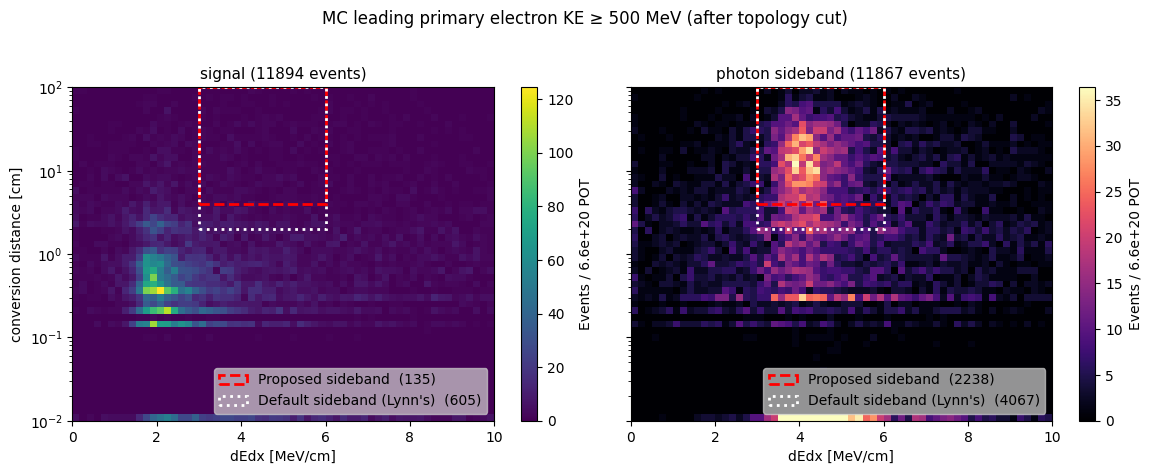

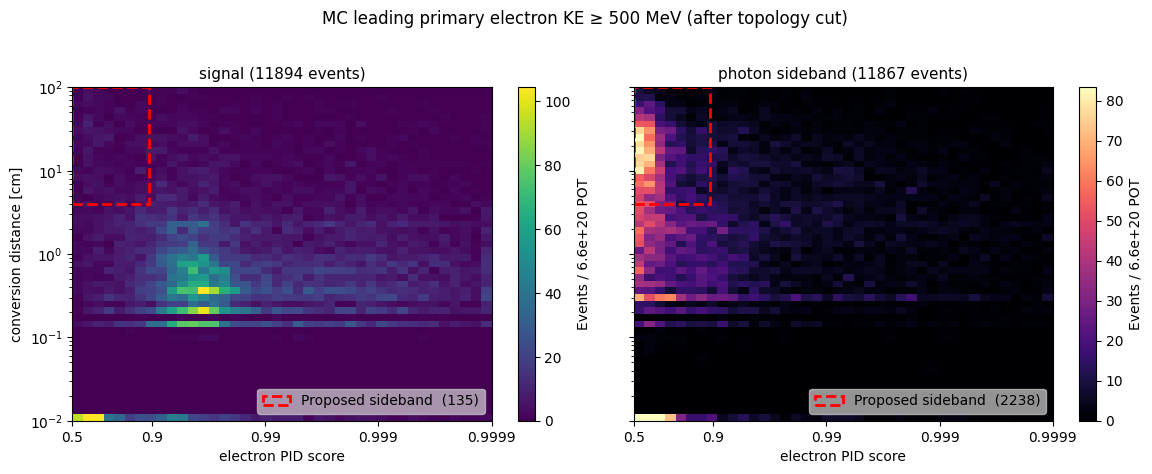

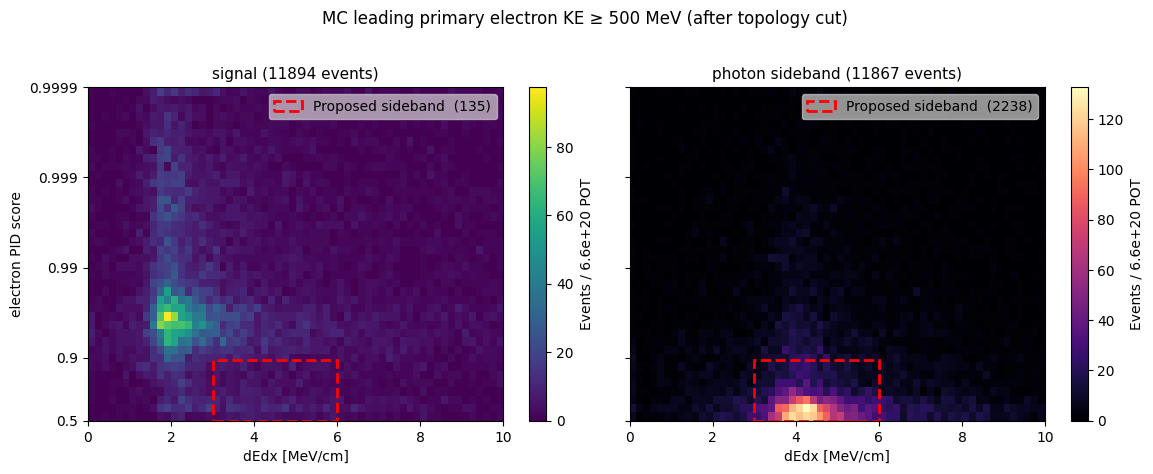

In [14]:
# Set 2: events passing the topology cut (≥1 primary reco electron ≥ 500 MeV), leading SPINE electron —
# the particle the signal selection and the sideband actually cut on.
sb2d_set(lambda d: d['sel_single_electron'], EP, 'topology',
         f'MC leading primary electron KE ≥ {KE_MIN:g} MeV (after topology cut)')

## 2.3 Sideband definitions: size, signal contamination, composition

In [15]:
POTS = [DATA_POT, 3e19, 1e20, 8.81e19]
 
def sb_table():
    rows = []
    for name in SIDEBANDS:
        d = PRED_T[in_sb(PRED_T, name)]
        tot = d['w'].sum()
        by = d.groupby('pcat')['w'].sum()
        f = lambda *cs: 100 * sum(by.get(c, 0) for c in cs) / tot if tot > 0 else np.nan
        row = {'sideband': name, 'νe CC FV %': f(0), 'νe all %': f(0, 1), 'νμCCπ0 %': f(2), 'NCπ0 %': f(3),
               'other ν %': f(4, 5, 9), 'cosmic+offbeam %': f(6, 7, 8)}
        for p in POTS:
            row[f'N @ {p:.2e}'] = tot * p / TARGET_POT
        if SHOW_DATA:
            row['data (dev)'] = int(in_sb(DATA, name).sum())
        rows.append(row)
    return pd.DataFrame(rows).set_index('sideband')
 
SB_TABLE = sb_table()
SB_TABLE.to_csv(f'{PLOT_DIR}/sideband_definitions.csv')
with pd.option_context('display.float_format', '{:.1f}'.format, 'display.width', 200):
    display(SB_TABLE)


,νe CC FV %,νe all %,νμCCπ0 %,NCπ0 %,other ν %,cosmic+offbeam %,N @ 4.48e+18,N @ 3.00e+19,N @ 1.00e+20,N @ 8.81e+19,data (dev)
sideband,,,,,,,,,,,
"Lynn TN: gap>2, 3<dE/dx<6",2.1,2.6,53.5,27.5,10.4,6.1,216.7,1452.5,4841.6,4265.5,149
"Lynn DAP cons.: gap>1, 3–6",2.9,3.4,53.4,27.0,10.2,6.0,228.8,1533.2,5110.8,4502.6,165
"Lynn DAP loose: gap>0.1, 3–6",6.7,7.2,49.7,25.7,9.4,8.0,264.7,1774.4,5914.6,5210.8,194
SPINE γ-PID leading shower,0.5,0.6,59.0,22.4,12.0,6.0,250.0,1675.4,5584.6,4920.0,188
SPINE γ-PID + Lynn TN box,0.4,0.4,58.7,25.0,11.3,4.6,176.9,1185.8,3952.6,3482.2,123
"current notebook (topology, PID-score inverted)",4.3,7.4,23.8,47.1,6.8,14.9,21.4,143.5,478.3,421.4,18
Lynn TN box + contained (≈D1),3.1,3.7,37.6,40.6,10.1,8.0,137.4,920.8,3069.4,2704.1,96


## 2.4 Control region: leading-shower energy by category and by reco PID (Lynn DAP Fig. 1 style)

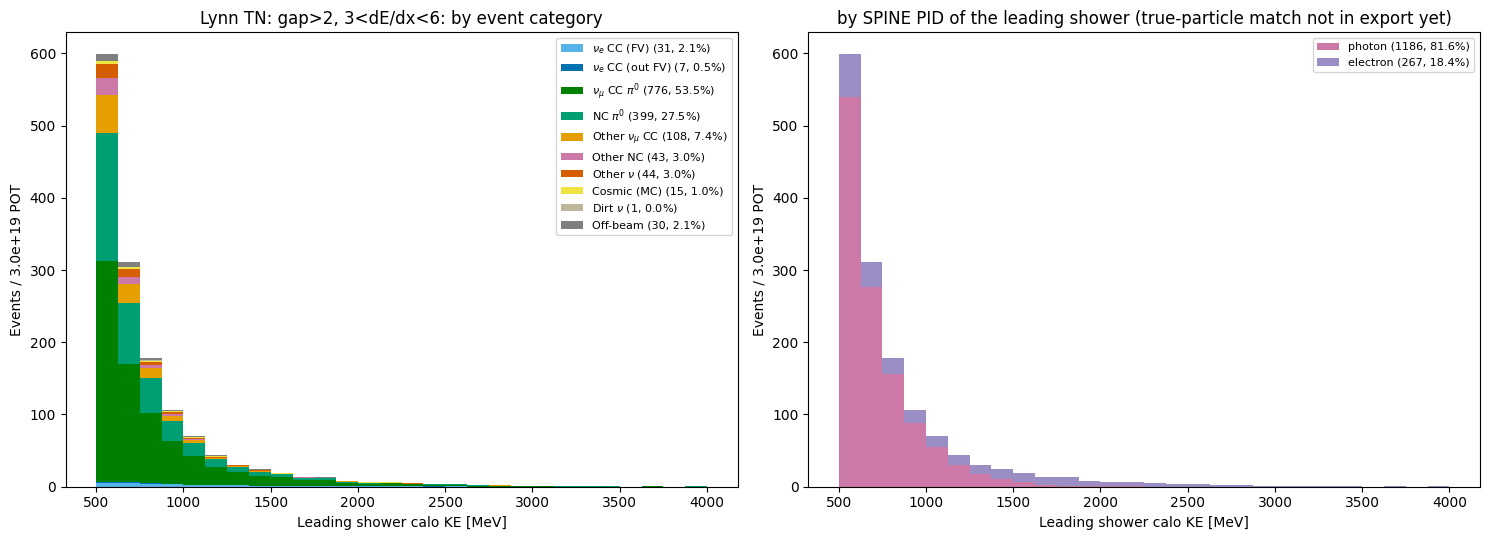

In [16]:
DISPLAY_POT = 3e19     # Lynn's first sideband request
def fig_sb_energy(name=SB_CHOICE, display_pot=DISPLAY_POT):
    d = PRED_T[in_sb(PRED_T, name)].copy()
    sc = display_pot / TARGET_POT
    bins = np.arange(KE_MIN, 4000 + 1, 125)
    fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
    stacked(axes[0], d, 'sh_calo_ke', bins, scale=sc)
    axes[0].set_title(f'{name}: by event category')
    d['pidcat'] = d['sh_pid'].fillna(-1).astype(int)
    stacked(axes[1], d[d.pidcat >= 0], 'sh_calo_ke', bins, cat='pidcat', cats=PIDCAT, order=[0, 1, 2, 3, 4], scale=sc)
    axes[1].set_title('by SPINE PID of the leading shower (true-particle match not in export yet)')
    for ax in axes:
        ax.set_xlabel('Leading shower calo KE [MeV]')
        ax.set_ylabel(f'Events / {display_pot:.1e} POT')
        ax.legend(fontsize=8)
    fig.tight_layout()
    savefig(fig, 'sideband_energy_' + re.sub(r'\W+', '_', name).strip('_'))
 
fig_sb_energy()


## 2.5 Signal contamination vs conversion-gap threshold (3 < dE/dx < 6 MeV/cm)

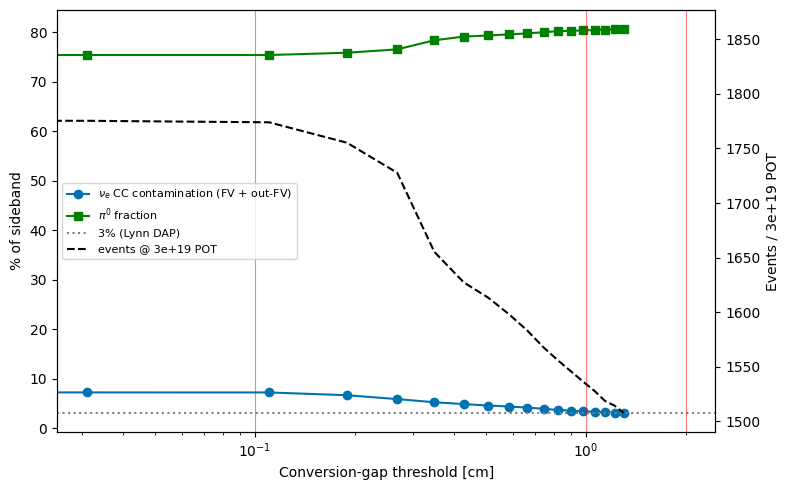

In [17]:
gaps = np.linspace(-1, 1.3, 30)
cont, nsb, pi0 = [], [], []
for g in gaps:
    d = PRED_T[box(PRED_T, g).fillna(False) & ~PRED_T[FINAL]]
    tot = d['w'].sum()
    cont.append(100 * d.loc[d.pcat.isin([0, 1]), 'w'].sum() / tot if tot else np.nan)
    pi0.append(100 * d.loc[d.pcat.isin([2, 3]), 'w'].sum() / tot if tot else np.nan)
    nsb.append(tot * DISPLAY_POT / TARGET_POT)
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(gaps, cont, 'o-', color='#0072B2', label=r'$\nu_e$ CC contamination (FV + out-FV)')
ax.plot(gaps, pi0, 's-', color='green', label=r'$\pi^0$ fraction')
ax.axhline(3, color='gray', ls=':', label='3% (Lynn DAP)')
ax.set_xscale('log'); ax.set_xlabel('Conversion-gap threshold [cm]'); ax.set_ylabel('% of sideband')
ax2 = ax.twinx(); ax2.plot(gaps, nsb, 'k--', label=f'events @ {DISPLAY_POT:.0e} POT'); ax2.set_ylabel(f'Events / {DISPLAY_POT:.0e} POT')
for g in (0.1, 1, 2):
    ax.axvline(g, color='red', lw=0.8, alpha=0.5)
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, fontsize=8, loc='center left')
fig.tight_layout(); savefig(fig, 'sideband_gap_scan')


## 2.6 Cut-flow efficiency and purity (Lynn TN Table 3 style, MC + dirt + off-beam at TARGET_POT)

In [18]:
def cutflow_table():
    den = meta.get('n_sig_truth_info') or meta['n_sig_presel']
    rows = []
    for s in [s for s in STAGES if s in set(CF.stage)]:
        c = CF[CF.stage == s]
        mc = c[c['sample'] == 'mc']
        sig_raw = mc.loc[mc.truth_cat == 0, 'n_raw'].sum()
        sig_w = mc.loc[mc.truth_cat == 0, 'n_w_target'].sum()
        tot_w = c.loc[c['sample'].isin(['mc', 'dirt', 'offbeam']), 'n_w_target'].sum()
        rows.append({'stage': s, 'efficiency %': 100 * sig_raw / den, 'purity %': 100 * sig_w / tot_w if tot_w else np.nan,
                     f'# νe CC @ {TARGET_POT:.1e}': sig_w, 'total pred.': tot_w,
                     'data (dev)': c.loc[c['sample'] == 'data', 'n_raw'].sum() if SHOW_DATA else np.nan})
    return pd.DataFrame(rows).set_index('stage')
 
CUTFLOW = cutflow_table()
CUTFLOW.to_csv(f'{PLOT_DIR}/cutflow_eff_pur.csv')
print(f"efficiency denominator: {'all true signal (truth_info)' if meta.get('n_sig_truth_info') else 'preselected true signal'}")
with pd.option_context('display.float_format', '{:.1f}'.format):
    display(CUTFLOW)
 
# ── Purity at the final stage: what is in the denominator ──────────────────────
fs = FINAL.replace('sel_', '')
c = CF[CF.stage == fs]
mcw = c[c['sample'] == 'mc'].groupby('truth_cat')['n_w_target'].sum()
comp = {name: mcw.get(k, 0.0) for k, name in
        [(0, 'νe CC FV (0)'), (1, 'νe CC out-FV (1)'), (2, 'νμ CC π0 (2)'), (3, 'NC π0 (3)'),
         (4, 'other νμ CC (4)'), (5, 'other NC (5)'), (6, 'other ν (6)'), (7, 'cosmic MC (7)')]}
comp['dirt'] = c.loc[c['sample'] == 'dirt', 'n_w_target'].sum()
comp['off-beam'] = c.loc[c['sample'] == 'offbeam', 'n_w_target'].sum()
comp = pd.Series(comp)
display(pd.DataFrame({f'events @ {TARGET_POT:.1e}': comp, '% of total': 100 * comp / comp.sum()}).round(1))
sig, b17 = comp.iloc[0], comp.iloc[1:8].sum()
print(f"purity νe/(MC cat 0–7)                        = {100*sig/(sig+b17):.1f}%   ← MC only")
print(f"purity νe/everything (MC + dirt ν + off-beam) = {100*sig/comp.sum():.1f}%   ← table above, comparable to Lynn's 80.1%")
 
# ── Who are the 'other ν' (cat 6) events? ────────────────────────────────────────
mc7 = EV['mc'][(EV['mc']['truth_cat'] == 6) & EV['mc'][FINAL]]
print(f"\nother ν (cat 6) at {fs}: {len(mc7)} raw MC events")
for col in ['ti_is_nu', 'ti_mct_index', 'ti_is_true_signal', 'ti_is_cc', 'ti_is_fv_true',
            'ti_has_true_electron', 'ti_has_pi0']:
    if col in mc7.columns:
        vc = mc7[col].value_counts(dropna=False).head(6)
        print(f"  {col:<22s} NaN={mc7[col].isna().mean():.0%}  " + ', '.join(f'{k}:{v}' for k, v in vc.items()))


efficiency denominator: all true signal (truth_info)


,efficiency %,purity %,# νe CC @ 6.6e+20,total pred.,data (dev)
stage,,,,,
precut,96.5,0.3,13094.3,4756118.2,39225
valid_flashmatch,96.5,0.3,13094.3,4756118.2,39225
fiducial,96.5,0.3,13094.3,4756118.2,39225
single_electron,87.7,37.8,11893.9,31471.6,206
electron_primary_score,84.5,40.4,11465.6,28364.4,190
electron_pid_score,73.1,59.2,9915.5,16743.7,114
vertex_distance,67.4,67.3,9146.9,13598.6,91
start_dedx,40.9,86.4,5544.4,6413.5,35


,events @ 6.6e+20,% of total
νe CC FV (0),5544.4,86.4
νe CC out-FV (1),62.2,1.0
νμ CC π0 (2),255.8,4.0
NC π0 (3),166.6,2.6
other νμ CC (4),41.1,0.6
other NC (5),29.3,0.5
other ν (6),62.2,1.0
cosmic MC (7),66.9,1.0
dirt,0.0,0.0
off-beam,184.9,2.9


purity νe/(MC cat 0–7)                        = 89.0%   ← MC only
purity νe/everything (MC + dirt ν + off-beam) = 86.4%   ← table above, comparable to Lynn's 80.1%

other ν (cat 6) at start_dedx: 53 raw MC events
  ti_is_nu               NaN=0%  True:53
  ti_mct_index           NaN=0%  0:31, 1:17, 2:4, 4:1
  ti_is_true_signal      NaN=0%  False:53
  ti_is_cc               NaN=0%  True:53
  ti_is_fv_true          NaN=0%  True:52, False:1
  ti_has_true_electron   NaN=0%  False:53
  ti_has_pi0             NaN=0%  False:30, True:23


## 2.7 True interaction mode: signal / background in signal region / sideband (Lynn TN Fig. 24 style)
Needs `ti_` columns with a mode and a true Eν; prints the available `ti_` columns otherwise.

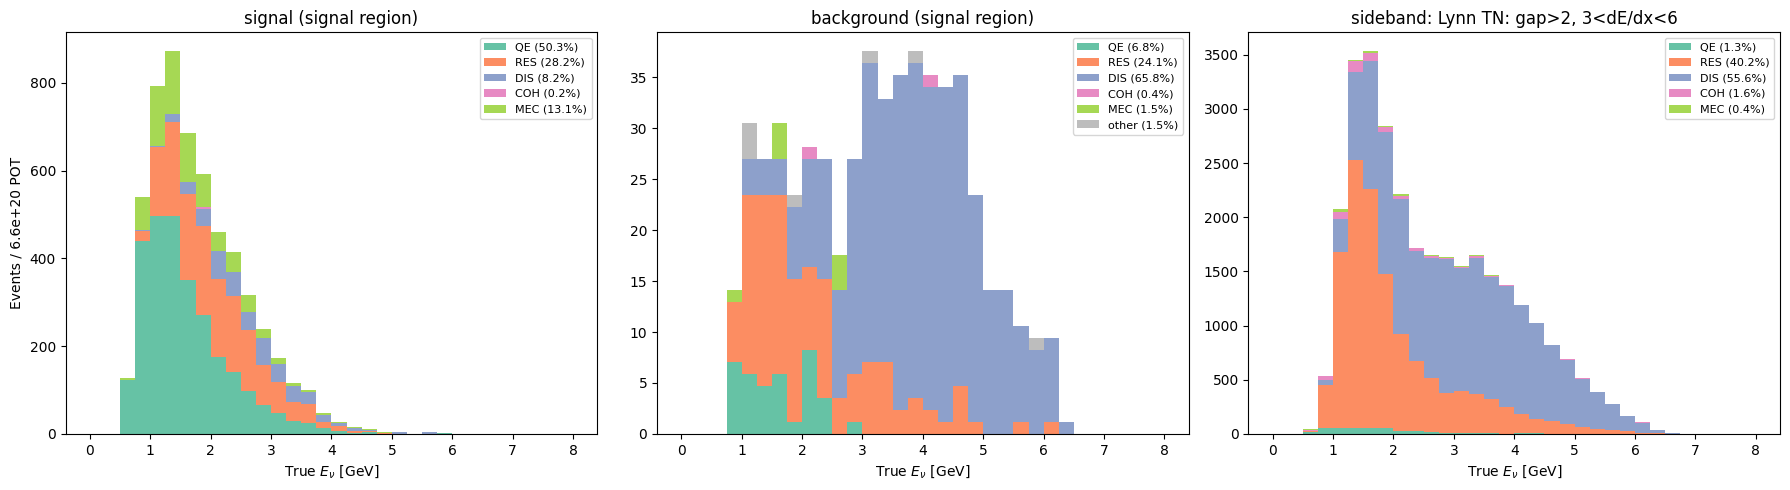

In [19]:
ti_cols = [c for c in EV['mc'].columns if c.startswith('ti_')]
MODE_COL = next((c for c in ti_cols if 'mode' in c.lower()), None)
ENU_COL  = next((c for c in ti_cols if c.lower() in ('ti_e', 'ti_nu_e', 'ti_enu', 'ti_nu_energy', 'ti_true_e', 'ti_true_nu_e')), None)
MODE_NAMES = {0: 'QE', 1: 'RES', 2: 'DIS', 3: 'COH', 10: 'MEC'}
MODE_COLS = {'QE': '#66c2a5', 'RES': '#fc8d62', 'DIS': '#8da0cb', 'COH': '#e78ac3', 'MEC': '#a6d854', 'other': '#bdbdbd'}
 
if MODE_COL is None or ENU_COL is None:
    print('mode / Eν columns not found among ti_ columns:', ti_cols)
    print('→ set MODE_COL / ENU_COL by hand (or add them to truth_info in make_nueCC_df).')
else:
    mc = PRED_T[PRED_T['sample'] == 'mc'].copy()
    mc['mode'] = mc[MODE_COL].map(MODE_NAMES).fillna('other')
    regions = [('signal (signal region)', mc[FINAL] & (mc.pcat == 0)),
               ('background (signal region)', mc[FINAL] & mc.pcat.between(1, 5)),
               (f'sideband: {SB_CHOICE}', in_sb(mc, SB_CHOICE))]
    bins = np.linspace(0, 8, 33)
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    for ax, (t, m) in zip(axes, regions):
        d = mc[m]
        bottom = np.zeros(len(bins) - 1)
        for mode, col in MODE_COLS.items():
            mm = d['mode'] == mode
            h, _ = np.histogram(d.loc[mm, ENU_COL], bins=bins, weights=d.loc[mm, 'w'])
            if h.sum() > 0:
                ax.bar(bins[:-1], h, np.diff(bins), bottom=bottom, align='edge', color=col,
                       label=f'{mode} ({100*h.sum()/d.w.sum():.1f}%)')
                bottom += h
        ax.set_title(t); ax.set_xlabel(r'True $E_\nu$ [GeV]'); ax.legend(fontsize=8)
    axes[0].set_ylabel(f'Events / {TARGET_POT:.1e} POT')
    fig.tight_layout(); savefig(fig, 'interaction_mode_breakdown')


## 2.8 Data checks (Gen1 dev sample only): time stability and sideband data/MC

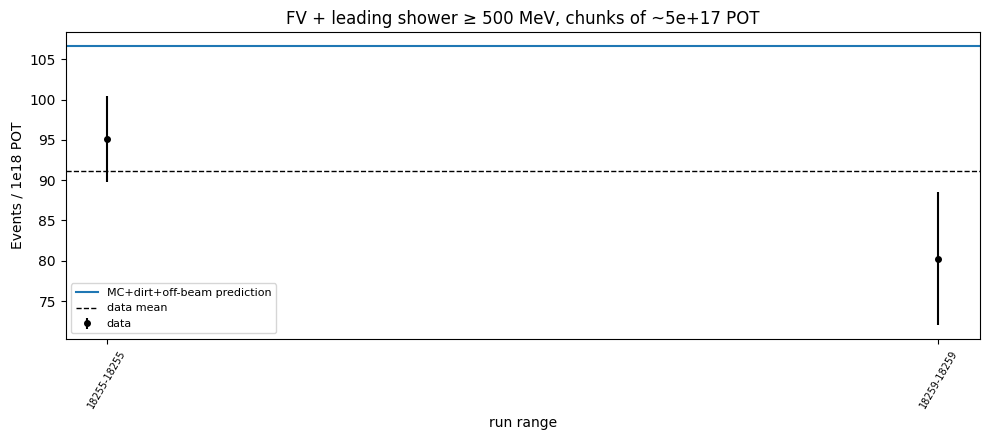

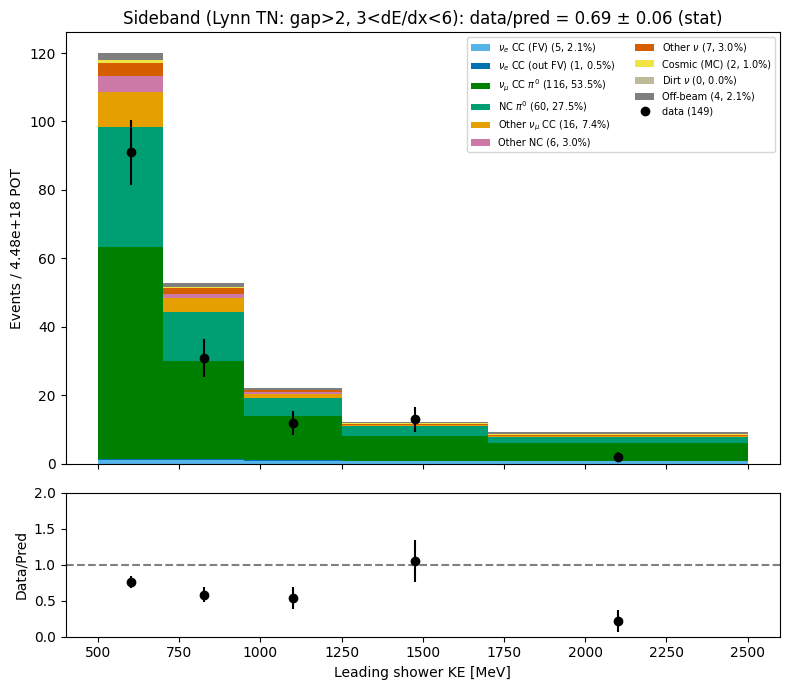

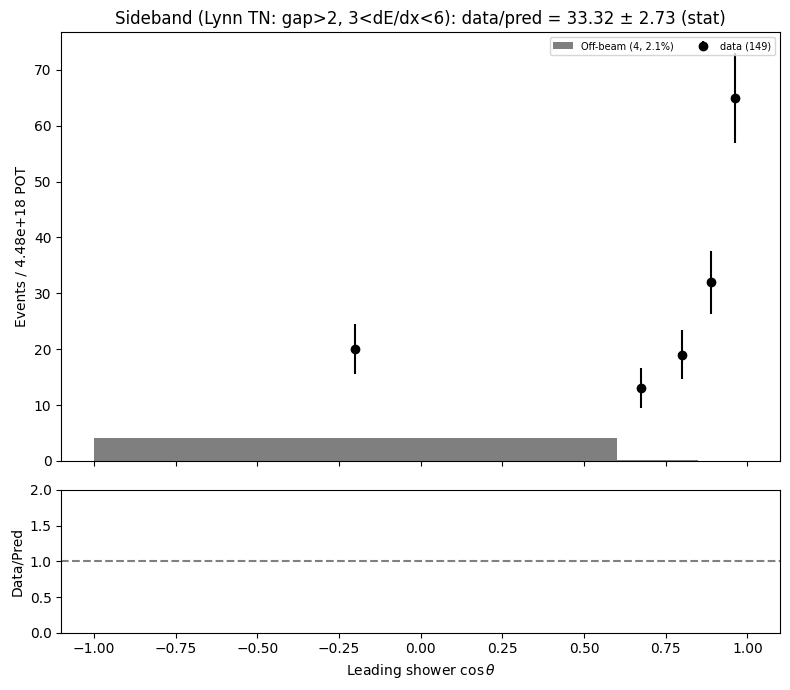

In [20]:
if not SHOW_DATA:
    print('data not shown (no data CSV, or production is not Gen1)')
else:
    # time stability: FV + leading shower ≥ KE_MIN, per run chunk, normalized per 1e18 POT
    if os.path.exists(f'{CSV_DIR}/data_pot_by_run.csv'):
        pbr = pd.read_csv(f'{CSV_DIR}/data_pot_by_run.csv').sort_values('run')
        CHUNK_POT = 5e17
        pbr['chunk'] = (pbr['pot'].cumsum() // CHUNK_POT).astype(int)
        chunks = pbr.groupby('chunk').agg(run_lo=('run', 'min'), run_hi=('run', 'max'), pot=('pot', 'sum'))
        n = DATA[SHOWER(DATA)].groupby('run').size()
        pbr['n'] = pbr['run'].map(n).fillna(0)
        chunks['n'] = pbr.groupby('chunk')['n'].sum()
        rate, err = chunks.n / chunks.pot * 1e18, np.sqrt(chunks.n) / chunks.pot * 1e18
        pred = PRED_D.loc[SHOWER(PRED_D).fillna(False), 'w'].sum() / DATA_POT * 1e18
        fig, ax = plt.subplots(figsize=(10, 4.5))
        ax.errorbar(np.arange(len(chunks)), rate, err, fmt='ko', ms=4, label='data')
        ax.axhline(pred, color='C0', label='MC+dirt+off-beam prediction')
        ax.axhline(chunks.n.sum() / chunks.pot.sum() * 1e18, color='k', ls='--', lw=1, label='data mean')
        ax.set_xticks(np.arange(len(chunks)))
        ax.set_xticklabels([f'{a}-{b}' for a, b in zip(chunks.run_lo, chunks.run_hi)], rotation=60, fontsize=7)
        ax.set_ylabel('Events / 1e18 POT'); ax.set_xlabel('run range')
        ax.set_title(f'FV + leading shower ≥ {KE_MIN:g} MeV, chunks of ~{CHUNK_POT:.0e} POT')
        ax.legend(fontsize=8); fig.tight_layout(); savefig(fig, 'data_time_stability')
 
    # sideband data/MC in the chosen definition
    for var, bins, xl in [('sh_calo_ke', np.array([500, 700, 950, 1250, 1700, 2500]), 'Leading shower KE [MeV]'),
                          ('sh_costheta', np.array([-1, 0.6, 0.75, 0.85, 0.925, 1.0]), r'Leading shower $\cos\theta$')]:
        d = PRED_D[in_sb(PRED_D, SB_CHOICE)]
        x = DATA.loc[in_sb(DATA, SB_CHOICE), var].clip(bins[0], bins[-1] - 1e-9)
        fig, (ax, ar) = plt.subplots(2, 1, figsize=(8, 7), sharex=True, gridspec_kw={'height_ratios': [3, 1]})
        tot = stacked(ax, d, var, bins)
        dc, _ = np.histogram(x, bins=bins)
        c = 0.5 * (bins[1:] + bins[:-1])
        ax.errorbar(c, dc, np.sqrt(dc), fmt='ko', label=f'data ({dc.sum()})')
        ax.set_ylabel(f'Events / {DATA_POT:.2e} POT'); ax.legend(fontsize=7, ncol=2)
        ax.set_title(f'Sideband ({SB_CHOICE}): data/pred = {dc.sum()/tot.sum():.2f} ± {np.sqrt(dc.sum())/tot.sum():.2f} (stat)')
        with np.errstate(divide='ignore', invalid='ignore'):
            ar.errorbar(c, dc / tot, np.sqrt(dc) / tot, fmt='ko')
        ar.axhline(1, color='gray', ls='--'); ar.set_ylim(0, 2); ar.set_ylabel('Data/Pred'); ar.set_xlabel(xl)
        fig.tight_layout(); savefig(fig, f'sideband_datamc_{var}')


## 2.9 Event lists for scanning in spinal-tap
Writes `saved_csvs/scan_lists/<name>.csv` (run, subrun, evt first). Feed a list to `find_events_h5.py`, which
returns the SPINE HDF5 file and entry for each event (what spinal-tap needs). Add your own masks at the end.

In [21]:
SCAN_DIR = f'{CSV_DIR}/scan_lists'
os.makedirs(SCAN_DIR, exist_ok=True)
SCAN_VARS = ['sh_calo_ke', 'sh_pid', 'sh_start_dedx', 'sh_vertex_distance', 'sh_costheta',
             'e_calo_ke', 'e_start_dedx', 'e_vertex_distance', 'e_pid_score_electron', 'e_primary_score',
             'n_photon_primary', 'n_electron_primary', 'n_muon_primary', 'n_proton_primary',
             'trk_length', 'vtx_x', 'vtx_y', 'vtx_z', 'ana_reco_ke', 'ana_reco_costheta']
 
 
def scan_list(df, mask, name):
    mask = pd.Series(mask, index=df.index).fillna(False).astype(bool)
    cols = [c for c in META_COLS + SCAN_VARS + [c for c in df.columns if c.startswith('sel_')] if c in df.columns]
    out = df.loc[mask, cols].sort_values([c for c in ('run', 'subrun', 'evt') if c in cols])
    out.to_csv(f'{SCAN_DIR}/{name}.csv', index=False)
    print(f'{name:<34s} {len(out):>5d} events → {SCAN_DIR}/{name}.csv')
    return out
 
 
if SHOW_DATA:
    scan_list(DATA, DATA[FINAL], 'data_final')
    scan_list(DATA, in_sb(DATA, SB_CHOICE), 'data_sideband')
    scan_list(DATA, DATA['sel_single_electron'] & ~DATA[FINAL], 'data_topology_failed_final')
    # example of a bin you want to look at: highest-KE bin at the final stage
    scan_list(DATA, DATA[FINAL] & (DATA['e_calo_ke'] >= 2200), 'data_final_ke_ge_2200')
scan_list(EV['mc'], (EV['mc']['truth_cat'] == 6) & EV['mc'][FINAL], 'mc_other_nu_final')
scan_list(EV['mc'], (EV['mc']['truth_cat'].isin([2, 3])) & EV['mc'][FINAL], 'mc_pi0_bkg_final')


data_final                            35 events → ./saved_csvs/scan_lists/data_final.csv
data_sideband                        149 events → ./saved_csvs/scan_lists/data_sideband.csv
data_topology_failed_final           171 events → ./saved_csvs/scan_lists/data_topology_failed_final.csv
data_final_ke_ge_2200                  3 events → ./saved_csvs/scan_lists/data_final_ke_ge_2200.csv
mc_other_nu_final                     53 events → ./saved_csvs/scan_lists/mc_other_nu_final.csv
mc_pi0_bkg_final                     360 events → ./saved_csvs/scan_lists/mc_pi0_bkg_final.csv


,run,subrun,evt,sample,truth_cat,idx0,idx1,idx2,int_id,sh_id,...,ana_reco_ke,ana_reco_costheta,sel_precut,sel_valid_flashmatch,sel_fiducial,sel_single_electron,sel_electron_primary_score,sel_electron_pid_score,sel_vertex_distance,sel_start_dedx
33097,52,55,24,mc,3,224309,3,1,1.0,1.0,...,2007.38550,0.945044,True,True,True,True,True,True,True,True
30918,73,32,39,mc,3,209360,4,3,3.0,6.0,...,716.49005,0.796395,True,True,True,True,True,True,True,True
38965,117,82,6,mc,2,263562,1,5,5.0,9.0,...,1678.42570,0.987290,True,True,True,True,True,True,True,True
8709,118,22,89,mc,2,57978,17,1,1.0,1.0,...,2266.37100,0.910363,True,True,True,True,True,True,True,True
9511,118,56,38,mc,2,63585,6,3,3.0,5.0,...,2559.17260,0.986677,True,True,True,True,True,True,True,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13094,4395,94,47,mc,3,87830,6,1,1.0,2.0,...,1289.68490,0.899024,True,True,True,True,True,True,True,True
5894,4405,99,20,mc,2,39229,3,0,0.0,0.0,...,776.97370,0.981912,True,True,True,True,True,True,True,True
14767,4417,41,40,mc,3,99053,5,3,3.0,6.0,...,617.56810,0.880857,True,True,True,True,True,True,True,True
3104,4431,62,38,mc,3,20540,4,0,0.0,3.0,...,1308.88810,0.992753,True,True,True,True,True,True,True,True


## 2.10 Data/MC mismatch finder → event lists ready for spinal-tap 
For each variable, histogram data vs prediction (MC incl. cat 7 + dirt + off-beam) at the stage
just BEFORE that variable is cut on (N-1 style), flag bins whose Poisson p-value < P_FLAG, and
write the data events in flagged bins (with h5_file / h5_entry) to scan_lists/mismatch/.
Deficit bins: data has too FEW events, so there is nothing missing to look at in data — the
list of over-predicted MC events (same bin) is written instead, for the MC SPINE files.

In [22]:
from math import lgamma, log, exp

H5_INDEX   = '/exp/sbnd/app/users/castalyf/h5_index_bnblight_dev.csv'   # built by find_events_h5.py
SHAPE_ONLY = True     # scale prediction to the data total first (the ~0.84 normalization is known)
P_FLAG     = 0.05     # flag bins with Poisson p below this
MIS_DIR    = f'{CSV_DIR}/scan_lists/mismatch'
os.makedirs(MIS_DIR, exist_ok=True)

CHECKS = [  # (variable, events must pass this stage, bin edges) — the stage is the cut BEFORE the variable's cut
    ('e_primary_score',      'sel_single_electron',        np.linspace(0, 1, 11)),
    ('e_pid_score_electron', 'sel_electron_primary_score', np.linspace(0, 1, 11)),
    ('e_vertex_distance',    'sel_electron_pid_score',     np.array([0, 0.25, 0.5, 1, 2, 3, 5, 10, 30])),
    ('e_start_dedx',         'sel_vertex_distance',        np.array([0, 1, 1.5, 2, 2.5, 3, 4, 6, 10])),
    ('e_calo_ke',            FINAL,                        np.array([500, 700, 1000, 1300, 1700, 2200, 3000])),
    ('sh_costheta',          FINAL,                        np.array([-1, 0.6, 0.75, 0.85, 0.925, 1.0])),
    ('vtx_x',                FINAL,                        np.linspace(-200, 200, 9)),
    ('vtx_z',                FINAL,                        np.linspace(0, 500, 11)),
]


PLAIN = {0: 'nueCC-FV', 1: 'nueCC-outFV', 2: 'numuCCpi0', 3: 'NCpi0', 4: 'numuCC-other', 5: 'NC-other',
         6: 'otherNu', 7: 'cosmicMC', 8: 'offbeam', 9: 'dirt'}


def _pois_cdf(k, mu):                       # P(N <= k | mu)
    if mu <= 0:
        return 1.0
    return min(1.0, sum(exp(i * log(mu) - mu - lgamma(i + 1)) for i in range(int(k) + 1)))


def _pvalue(n, mu):                         # one-sided, in the direction of the deviation
    return 1.0 - _pois_cdf(n - 1, mu) if n > mu else _pois_cdf(n, mu)


_h5 = None
if os.path.exists(H5_INDEX):
    _h5 = pd.read_csv(H5_INDEX).rename(columns={'file': 'h5_file', 'entry': 'h5_entry', 'event': 'evt'})
else:
    print(f'h5 index not found at {H5_INDEX} → lists will have run/subrun/evt only')


def _locate(df):
    if _h5 is None or df.empty or not {'run', 'subrun', 'evt'} <= set(df.columns):
        return df
    k = ['run', 'subrun', 'evt']
    m = df.merge(_h5[k + ['h5_file', 'h5_entry']].drop_duplicates(k), on=k, how='left')
    return m[['h5_file', 'h5_entry'] + [c for c in m.columns if c not in ('h5_file', 'h5_entry')]]


def mismatch(var, stage, bins, shape_only=SHAPE_ONLY, p_flag=P_FLAG, show=True):
    pm = SHOWER(PRED_D).fillna(False) & PRED_D[stage]
    dm = SHOWER(DATA).fillna(False) & DATA[stage]
    p, d = PRED_D[pm], DATA[dm]
    clip = lambda s: s.clip(bins[0], bins[-1] - 1e-9)
    pb = np.digitize(clip(p[var]), bins) - 1
    db = np.digitize(clip(d[var]), bins) - 1
    mu = np.bincount(pb[p[var].notna()], weights=p.loc[p[var].notna(), 'w'], minlength=len(bins) - 1)
    n = np.bincount(db[d[var].notna()], minlength=len(bins) - 1).astype(float)
    norm = n.sum() / mu.sum() if (shape_only and mu.sum() > 0) else 1.0
    mu = mu * norm
    rows = []
    for i in range(len(bins) - 1):
        comp = p[pb == i].groupby('pcat')['w'].sum().sort_values(ascending=False) * norm
        top = ', '.join(f'{PLAIN.get(c, c)} {v:.1f}' for c, v in comp.head(3).items())
        rows.append(dict(bin=f'[{bins[i]:g}, {bins[i+1]:g})', data=int(n[i]), pred=mu[i],
                         ratio=n[i] / mu[i] if mu[i] > 0 else np.nan,
                         pull=(n[i] - mu[i]) / np.sqrt(mu[i]) if mu[i] > 0 else np.nan,
                         p=_pvalue(n[i], mu[i]), top_pred=top))
    tab = pd.DataFrame(rows)
    tab['flag'] = np.where(tab.p < p_flag, np.where(tab.data > tab.pred, 'EXCESS', 'DEFICIT'), '')

    written = []
    for i, r in tab[tab.flag != ''].iterrows():
        tag = f"{var}_bin{i}_{r.flag.lower()}"
        if r.flag == 'EXCESS':
            out = _locate(d[db == i].sort_values(var))
        else:   # over-predicted MC events in this bin, highest-weight categories first
            out = p[(pb == i) & (p['sample'] == 'mc')].sort_values(['pcat', 'w'], ascending=[True, False])
        cols = [c for c in ['h5_file', 'h5_entry'] + META_COLS + [var] + SCAN_VARS if c in out.columns]
        out[list(dict.fromkeys(cols))].to_csv(f'{MIS_DIR}/{tag}.csv', index=False)
        written.append(f'{tag}.csv ({len(out)} {"data" if r.flag == "EXCESS" else "MC"} events)')

    if show:
        print(f"\n{var}  @ {stage.replace('sel_', '')}   data={int(n.sum())}  pred={mu.sum()/norm:.1f}"
              + (f"  (prediction scaled ×{norm:.2f} for shape)" if shape_only else ''))
        with pd.option_context('display.float_format', '{:.2f}'.format, 'display.width', 200,
                               'display.max_colwidth', 70):
            display(tab)
        for w in written:
            print('   →', w)
    return tab


MISMATCH = {}
if not SHOW_DATA:
    print('no data shown (Gen2 / data not exported)')
else:
    for var, stage, bins in CHECKS:
        if var in DATA.columns and stage in DATA.columns:
            MISMATCH[var] = mismatch(var, stage, bins)
    summ = pd.concat({v: t[t.flag != ''] for v, t in MISMATCH.items()}, names=['variable']).reset_index(level=0)
    print('\n══ flagged bins (all variables) ══')
    display(summ[['variable', 'bin', 'data', 'pred', 'ratio', 'p', 'flag', 'top_pred']]
            if len(summ) else pd.DataFrame({'result': ['no bin with p < %.2f' % P_FLAG]}))

    # every data event that sits in at least one EXCESS bin, with how many times it was flagged
    hits = []
    for var, stage, bins in CHECKS:
        t = MISMATCH.get(var)
        if t is None:
            continue
        for i in t.index[t.flag == 'EXCESS']:
            lo, hi = bins[i], bins[i + 1]
            x = DATA[var].clip(bins[0], bins[-1] - 1e-9)
            m = SHOWER(DATA).fillna(False) & DATA[stage] & (x >= lo) & (x < hi)
            hits.append(DATA.loc[m, ['run', 'subrun', 'evt']].assign(why=f'{var} in [{lo:g},{hi:g})'))
    if hits:
        h = pd.concat(hits).groupby(['run', 'subrun', 'evt'])['why'].agg(lambda s: '; '.join(s)).reset_index()
        h['n_flags'] = h['why'].str.count(';') + 1
        h = _locate(h.merge(DATA, on=['run', 'subrun', 'evt'], how='left')).sort_values('n_flags', ascending=False)
        keep = [c for c in ['h5_file', 'h5_entry', 'run', 'subrun', 'evt', 'n_flags', 'why'] + SCAN_VARS if c in h.columns]
        h[keep].to_csv(f'{MIS_DIR}/data_events_in_excess_bins.csv', index=False)
        print(f'\n{len(h)} data events sit in ≥1 excess bin → {MIS_DIR}/data_events_in_excess_bins.csv')
        display(h[keep[:8]].head(15))


e_primary_score  @ single_electron   data=206  pred=213.4  (prediction scaled ×0.97 for shape)


,bin,data,pred,ratio,pull,p,top_pred,flag
0,"[0, 0.1)",0,0.14,0.00,-0.38,0.87,"offbeam 0.1, cosmicMC 0.0",
1,"[0.1, 0.2)",0,0.00,NaN,NaN,1.00,,
2,"[0.2, 0.3)",0,0.00,NaN,NaN,1.00,,
3,"[0.3, 0.4)",0,0.00,NaN,NaN,1.00,,
4,"[0.4, 0.5)",0,0.00,NaN,NaN,1.00,,
5,"[0.5, 0.6)",0,0.16,0.00,-0.40,0.85,"numuCC-other 0.1, numuCCpi0 0.0, NC-other 0.0",
6,"[0.6, 0.7)",0,0.21,0.00,-0.46,0.81,"NC-other 0.1, numuCC-other 0.1, numuCCpi0 0.0",
7,"[0.7, 0.8)",0,0.27,0.00,-0.52,0.77,"numuCCpi0 0.1, numuCC-other 0.1, NC-other 0.0",
8,"[0.8, 0.9)",0,0.68,0.00,-0.82,0.51,"numuCC-other 0.2, NCpi0 0.1, numuCCpi0 0.1",
9,"[0.9, 1)",206,204.54,1.01,0.10,0.47,"nueCC-FV 77.8, NCpi0 39.9, numuCCpi0 37.3",



e_pid_score_electron  @ electron_primary_score   data=190  pred=192.4  (prediction scaled ×0.99 for shape)


,bin,data,pred,ratio,pull,p,top_pred,flag
0,"[0, 0.1)",0,0.00,NaN,NaN,1.00,,
1,"[0.1, 0.2)",0,0.00,NaN,NaN,1.00,,
2,"[0.2, 0.3)",0,0.00,NaN,NaN,1.00,,
3,"[0.3, 0.4)",0,0.00,NaN,NaN,1.00,,
4,"[0.4, 0.5)",0,0.00,NaN,NaN,1.00,,
5,"[0.5, 0.6)",14,17.41,0.80,-0.82,0.25,"NCpi0 7.7, numuCCpi0 3.6, offbeam 2.4",
6,"[0.6, 0.7)",25,25.92,0.96,-0.18,0.48,"NCpi0 9.2, numuCCpi0 4.7, offbeam 3.8",
7,"[0.7, 0.8)",19,16.90,1.12,0.51,0.34,"NCpi0 5.3, numuCCpi0 3.6, offbeam 2.6",
8,"[0.8, 0.9)",22,19.09,1.15,0.67,0.28,"nueCC-FV 4.9, NCpi0 4.7, numuCCpi0 4.3",
9,"[0.9, 1)",110,110.68,0.99,-0.06,0.50,"nueCC-FV 65.9, numuCCpi0 15.2, NCpi0 10.9",



e_vertex_distance  @ electron_pid_score   data=114  pred=113.6  (prediction scaled ×1.00 for shape)


,bin,data,pred,ratio,pull,p,top_pred,flag
0,"[0, 0.25)",4,18.80,0.21,-3.41,0.00,"nueCC-FV 14.9, NCpi0 1.5, numuCCpi0 0.8",DEFICIT
1,"[0.25, 0.5)",35,29.89,1.17,0.94,0.20,"nueCC-FV 18.7, offbeam 4.2, NCpi0 2.3",
2,"[0.5, 1)",22,20.02,1.10,0.44,0.36,"nueCC-FV 14.9, numuCCpi0 2.1, NCpi0 1.2",
3,"[1, 2)",22,12.39,1.78,2.73,0.01,"nueCC-FV 7.6, numuCCpi0 2.6, NCpi0 1.1",EXCESS
4,"[2, 3)",7,8.05,0.87,-0.37,0.45,"nueCC-FV 4.5, numuCCpi0 1.9, NCpi0 0.7",
5,"[3, 5)",2,5.79,0.35,-1.57,0.07,"nueCC-FV 2.5, numuCCpi0 1.7, NCpi0 0.9",
6,"[5, 10)",6,6.46,0.93,-0.18,0.53,"nueCC-FV 1.9, numuCCpi0 1.8, NCpi0 1.2",
7,"[10, 30)",16,12.60,1.27,0.96,0.20,"numuCCpi0 3.0, nueCC-FV 2.5, NCpi0 2.5",


... (10 outputs left out)


══ flagged bins (all variables) ══


,variable,bin,data,pred,ratio,p,flag,top_pred
0,e_vertex_distance,"[0, 0.25)",4,18.798206,0.212786,4.460650e-05,DEFICIT,"nueCC-FV 14.9, NCpi0 1.5, numuCCpi0 0.8"
3,e_vertex_distance,"[1, 2)",22,12.390431,1.775564,8.564982e-03,EXCESS,"nueCC-FV 7.6, numuCCpi0 2.6, NCpi0 1.1"
7,e_start_dedx,"[6, 10)",31,21.298882,1.455475,2.837863e-02,EXCESS,"nueCC-FV 10.0, numuCCpi0 3.6, offbeam 3.2"
0,sh_costheta,"[-1, 0.6)",3,28.975410,0.103536,1.174257e-09,DEFICIT,offbeam 29.0
1,sh_costheta,"[0.6, 0.75)",7,1.721311,4.066667,2.009157e-03,EXCESS,offbeam 1.7
2,sh_costheta,"[0.75, 0.85)",6,1.147541,5.228571,1.198827e-03,EXCESS,offbeam 1.1
3,sh_costheta,"[0.85, 0.925)",7,2.295082,3.050000,9.260955e-03,EXCESS,offbeam 2.3
4,sh_costheta,"[0.925, 1)",12,0.860656,13.942857,1.561109e-10,EXCESS,offbeam 0.9



68 data events sit in ≥1 excess bin → ./saved_csvs/scan_lists/mismatch/data_events_in_excess_bins.csv


,h5_file,h5_entry,run,subrun,evt,n_flags,why,sh_calo_ke
19,/pnfs/sbn/persistent/users/mueller/osc/sbnd/hd...,11,18255,1,214401,2,"e_vertex_distance in [1,2); sh_costheta in [0....",593.562256
53,/pnfs/sbn/persistent/users/mueller/osc/sbnd/hd...,2,18259,1,64285,2,"e_vertex_distance in [1,2); sh_costheta in [0....",650.346069
40,/pnfs/sbn/persistent/users/mueller/osc/sbnd/hd...,29,18255,1,422851,2,"e_vertex_distance in [1,2); sh_costheta in [0....",994.281616
36,/pnfs/sbn/persistent/users/mueller/osc/sbnd/hd...,0,18255,1,358057,2,"e_vertex_distance in [1,2); e_start_dedx in [6...",512.696411
35,/pnfs/sbn/persistent/users/mueller/osc/sbnd/hd...,33,18255,1,331926,2,"e_vertex_distance in [1,2); e_start_dedx in [6...",717.766724
1,/pnfs/sbn/persistent/users/mueller/osc/sbnd/hd...,42,18255,1,8157,2,"e_vertex_distance in [1,2); e_start_dedx in [6...",1400.955322
33,/pnfs/sbn/persistent/users/mueller/osc/sbnd/hd...,33,18255,1,307765,2,"e_vertex_distance in [1,2); e_start_dedx in [6...",2049.760254
29,/pnfs/sbn/persistent/users/mueller/osc/sbnd/hd...,7,18255,1,269774,2,"e_vertex_distance in [1,2); sh_costheta in [0....",1015.376587
46,/pnfs/sbn/persistent/users/mueller/osc/sbnd/hd...,9,18255,1,489330,2,"e_vertex_distance in [1,2); sh_costheta in [0....",1164.731934
47,/pnfs/sbn/persistent/users/mueller/osc/sbnd/hd...,33,18255,1,501694,2,"e_vertex_distance in [1,2); e_start_dedx in [6...",1651.851685


## 2.11 Start dE/dx: per-bin numbers behind the normalised distribution
Same population, variable and binning as the start dE/dx panel of the cumulative threshold scan in `nue_selection.ipynb`:
MC events after the conversion-gap cut, leading primary electron (`lp_start_dedx`), 50 bins in 0–8 MeV/cm, signal = truth_cat 0,
background = all other MC. The density columns are the two curves drawn on that plot (each normalised to area 1 in 0–8).
`dE/dx < hi` columns give what a cut at the bin's upper edge keeps (relative to all events before the cut, incl. those outside 0–8).

In [26]:
DEDX_BINS = np.linspace(0.0, 8.0, 51)                     # = threshold_plots_cumulative upper panel
MAX_EFF_LOSS = 0.05                                        # max fraction of pre-cut signal the dE/dx cut may remove
PRE = f"sel_{STAGES[STAGES.index('start_dedx') - 1]}"      # stage before the dE/dx cut
mc  = EV['mc'][EV['mc'][PRE]]
x   = mc[EP + 'start_dedx'].to_numpy(float)
w   = mc['w_target'].to_numpy(float)
sg  = (mc['truth_cat'] == 0).to_numpy()

if np.isnan(x).mean() > 0.05:
    raise RuntimeError(f'{100*np.isnan(x).mean():.0f}% of events have no {EP}start_dedx — the CSVs do not match '
                       'the selection; re-run the export (RUN_EXPORT=True) with the current DF_FILE')
nS, _ = np.histogram(x[sg],  bins=DEDX_BINS, weights=w[sg])
nB, _ = np.histogram(x[~sg], bins=DEDX_BINS, weights=w[~sg])
width = np.diff(DEDX_BINS)
S_all, B_all = w[sg].sum(), w[~sg].sum()                   # incl. NaN / outside 0–8 (they fail any dE/dx < cut)
cS = np.array([w[sg  & (x < h)].sum() for h in DEDX_BINS[1:]])
cB = np.array([w[~sg & (x < h)].sum() for h in DEDX_BINS[1:]])
# absolute efficiency after the cut, same definition as cutflow_table (raw true-signal count / denominator)
EFF_DEN = meta.get('n_sig_truth_info') or meta['n_sig_presel']
cS_raw  = np.array([(sg & (x < h)).sum() for h in DEDX_BINS[1:]])
eff_pre = sg.sum() / EFF_DEN
eff     = cS_raw / EFF_DEN
pur     = np.where(cS + cB > 0, cS / np.maximum(cS + cB, 1e-12), np.nan)

tab = pd.DataFrame({
    'lo': DEDX_BINS[:-1], 'hi': DEDX_BINS[1:],
    'signal': nS, 'bkg': nB,
    'sig density': nS / (nS.sum() * width), 'bkg density': nB / (nB.sum() * width),
    'purity in bin': np.where(nS + nB > 0, nS / np.maximum(nS + nB, 1e-12), np.nan),
    'sig kept (<hi)': cS / S_all, 'bkg kept (<hi)': cB / B_all,
    'purity (<hi)': pur,
    'eff (<hi)': eff, 'eff×pur (<hi)': eff * pur,
})
tab['sig > bkg'] = np.where(tab['sig density'] > tab['bkg density'], '◀', '')

# threshold choice: (a) max eff×purity; (b) highest purity that keeps ≥ (1 − MAX_EFF_LOSS) of pre-cut signal
i_ep = int(np.nanargmax(eff * pur))
ok = cS / S_all >= 1 - MAX_EFF_LOSS
i_pl = int(np.nanargmax(np.where(ok, pur, -np.inf))) if ok.any() else None
tab['choice'] = ''
tab.loc[i_ep, 'choice'] += 'max eff×pur '
if i_pl is not None:
    tab.loc[i_pl, 'choice'] += f'best pur, loss≤{100*MAX_EFF_LOSS:.0f}%'
print(f"{PRE}: signal {S_all:.0f}, background {B_all:.0f} MC events @ {TARGET_POT:.1e} POT "
      f"(no {EP}start_dedx: sig {w[sg & ~np.isfinite(x)].sum():.0f}, bkg {w[~sg & ~np.isfinite(x)].sum():.0f}; "
      f"> 8: sig {w[sg & (x >= 8)].sum():.0f}, bkg {w[~sg & (x >= 8)].sum():.0f})")
fmt = {'lo': '{:.2f}', 'hi': '{:.2f}', 'signal': '{:.1f}', 'bkg': '{:.1f}', 'sig density': '{:.3f}',
       'bkg density': '{:.3f}', 'purity in bin': '{:.3f}', 'sig kept (<hi)': '{:.3f}',
       'bkg kept (<hi)': '{:.3f}', 'purity (<hi)': '{:.3f}', 'eff (<hi)': '{:.3f}', 'eff×pur (<hi)': '{:.3f}'}
print(f"efficiency before the dE/dx cut: {100*eff_pre:.1f}%  "
      f"(denominator: {'all true signal (truth_info)' if meta.get('n_sig_truth_info') else 'preselected true signal'})")
for lbl, i in [('max eff×purity', i_ep), (f'best purity, signal loss ≤ {100*MAX_EFF_LOSS:.0f}%', i_pl)]:
    if i is None:
        print(f"  {lbl:<34s}: no threshold keeps ≥ {100*(1-MAX_EFF_LOSS):.0f}% of the signal")
        continue
    print(f"  {lbl:<34s}: dE/dx < {DEDX_BINS[i+1]:.2f}  →  eff {100*eff[i]:.1f}% "
          f"(−{100*(eff_pre-eff[i]):.1f} pts, keeps {100*cS[i]/S_all:.1f}% of pre-cut signal), "
          f"purity {100*pur[i]:.1f}% (pre-cut {100*S_all/(S_all+B_all):.1f}%), bkg kept {100*cB[i]/B_all:.1f}%")
display(tab.style.format(fmt).hide(axis='index'))
tab.to_csv(f'{PLOT_DIR}/dedx_per_bin.csv', index=False)

sel_vertex_distance: signal 9147, background 3530 MC events @ 6.6e+20 POT (no lp_start_dedx: sig 0, bkg 0; > 8: sig 947, bkg 704)
efficiency before the dE/dx cut: 67.4%  (denominator: all true signal (truth_info))
  max eff×purity                    : dE/dx < 8.00  →  eff 60.4% (−7.0 pts, keeps 89.6% of pre-cut signal), purity 74.4% (pre-cut 72.2%), bkg kept 80.1%
  best purity, signal loss ≤ 5%     : no threshold keeps ≥ 95% of the signal


lo,hi,signal,bkg,sig density,bkg density,purity in bin,sig kept (<hi),bkg kept (<hi),purity (<hi),eff (<hi),eff×pur (<hi),sig > bkg,choice
0.00,0.16,36.4,48.1,0.028,0.106,0.431,0.004,0.014,0.431,0.003,0.001,,
0.16,0.32,11.7,8.2,0.009,0.018,0.588,0.005,0.016,0.461,0.004,0.002,,
0.32,0.48,22.3,15.3,0.017,0.034,0.594,0.008,0.020,0.496,0.005,0.003,,
0.48,0.64,12.9,8.2,0.010,0.018,0.611,0.009,0.023,0.511,0.006,0.003,,
0.64,0.80,39.9,15.3,0.030,0.034,0.723,0.013,0.027,0.565,0.009,0.005,,
0.80,0.96,34.0,25.8,0.026,0.057,0.569,0.017,0.034,0.565,0.012,0.007,,
0.96,1.12,48.1,31.7,0.037,0.070,0.603,0.022,0.043,0.574,0.015,0.009,,
1.12,1.28,73.9,37.5,0.056,0.083,0.663,0.031,0.054,0.595,0.021,0.012,,
1.28,1.44,138.5,21.1,0.106,0.047,0.868,0.046,0.060,0.664,0.031,0.020,◀,
1.44,1.60,241.7,44.6,0.184,0.099,0.844,0.072,0.072,0.721,0.049,0.035,◀,


In [24]:
pause

NameError: name 'pause' is not defined

In [ ]:
%reset -f